# for picking best health_score and terminal models
## based on amount of advantage accumulated and how in-distribution the policy is

## the formula is: 
One thing worth flagging for the paper's methods section, since you're now using three sequential criteria: state the full selection cascade explicitly and in this order — (1) exclude own-critic advantage ≤ 0 [training-validity gate], (2) exclude alphas at/above the SARSA-advantage instability onset [reliability gate], (3) among survivors, select by highest occupancy support, breaking ties by SARSA-advantage [safety-first final pick]. That's a fully principled, three-stage, pre-specified procedure — worth writing it as a single clear paragraph or even a small flowchart/algorithm box, since a reviewer will want to see this reasoning laid out plainly rather than reconstructed from separate analyses.

In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_cql_alpha_sweep as eval_cql

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])


[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

# get paths to the models

In [2]:
cohort = "picu"
# health_cohort = "sepsis_picu"
health_cohort = "picu" # dynamic deephit trained on all picu patients, not just sepsis patients

if cohort == "picu":    
    if health_cohort == "picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")

    elif health_cohort == "sepsis_picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/sepsis_picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")


Using basic_q_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Using cql_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset


In [3]:
cql_hs_dir      = os.path.join(cql_model_dir, "with_actions", "health_score_change_only", "alpha_sweep")
cql_term_dir    = os.path.join(cql_model_dir, "with_actions", "terminal_only", "alpha_sweep")
sarsa_hs_dir    = os.path.join(basic_q_dir, "with_actions", "health_score_change_only", "five_seeds")
sarsa_term_dir  = os.path.join(basic_q_dir, "with_actions", "terminal_only", "five_seeds")   # confirm

# load health score models

In [4]:
hs_study = R.make_study(cql_hs_dir, group_by=("cql_alpha",), name="CQL alpha sweep (health score)")
_ = hs_study.check(ignore=R.DEFAULT_IGNORE_KEYS | {"ratio_of_fluid_to_vaso"})
sarsa_hs_study = R.make_study(sarsa_hs_dir, name="SARSA (health score)")
_ = sarsa_hs_study.check()

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep:
    vaso_reward_coefficient: saved=0.1 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Study 'CQL alpha sweep (health score)': 32 group(s), 160 run(s), seeds [0, 1, 2, 3, 4]
  between groups:
      cql_alpha                                {'cql_alpha=0.0': 0.0, 'cq

In [5]:
cql_hs_models = M.load_study_models(hs_study)
sarsa_hs_models = M.load_study_models(sarsa_hs_study)

  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0 seed 0: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0 seed 1: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0 seed 2: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0 seed 3: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0 seed 4: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0001 seed 0: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0001 seed 1: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0001 seed 2: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0001 seed 3: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.0001 seed 4: actor, critic)
  loaded LoadedModel(CQL alpha sweep (health score) cql_alpha=0.001 seed 0: actor, critic)
  lo

# load data

In [6]:
print(len(hs_study.data_identities()), "CQL identities (expect 5);",
      {v.short() for v in sarsa_hs_study.data_identities().values()} <=
      {v.short() for v in hs_study.data_identities().values()}, "(SARSA shares them)")

store = D.DataStore(keep=("train", "val"))
paired = store.pair({k: v for k, v in cql_hs_models.items() if k == (0.03,)}, split="val")
display(D.check_rows_aligned({s: p for s, (m, p) in paired[(0.03,)].items()}))

5 CQL identities (expect 5); True (SARSA shares them)
  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  bu

,n_rows,same_index_ptr,same_actions,same_health_score,same_rewards,same_states
0,90152,True,True,True,True,True
1,90152,True,True,True,True,False
2,90152,True,True,True,True,False
3,90152,True,True,True,True,False
4,90152,True,True,True,True,False


# run sweep

In [7]:
df_hs = eval_cql.run_alpha_sweep_analysis(cql_hs_models, sarsa_hs_models, store, n_severity_bins=200)
display(eval_cql.summarize_by_alpha(df_hs))

alpha=0          (deterministic, val, 5 seeds)  own_norm=+0.1242  sarsa_norm=+0.5598 [+0.5027, +0.6043]  occupancy=92.2%  (1.8s)
alpha=0.0001     (deterministic, val, 5 seeds)  own_norm=+0.1237  sarsa_norm=+0.5597 [+0.5034, +0.6030]  occupancy=90.8%  (0.9s)
alpha=0.001      (deterministic, val, 5 seeds)  own_norm=+0.1170  sarsa_norm=+0.5574 [+0.5026, +0.5976]  occupancy=90.0%  (0.9s)
alpha=0.005      (deterministic, val, 5 seeds)  own_norm=+0.0854  sarsa_norm=+0.5173 [+0.4708, +0.5515]  occupancy=88.6%  (0.9s)
alpha=0.01       (deterministic, val, 5 seeds)  own_norm=+0.0404  sarsa_norm=+0.4047 [+0.3364, +0.4350]  occupancy=97.4%  (0.9s)
alpha=0.015      (deterministic, val, 5 seeds)  own_norm=+0.0321  sarsa_norm=+0.3346 [+0.2717, +0.3650]  occupancy=99.3%  (0.9s)
alpha=0.02       (deterministic, val, 5 seeds)  own_norm=+0.0246  sarsa_norm=+0.2973 [+0.1962, +0.3381]  occupancy=99.4%  (0.9s)
alpha=0.021      (deterministic, val, 5 seeds)  own_norm=+0.0228  sarsa_norm=+0.2880 [+0.1969, +0

own_adv                               own_adv_norm            \
            mean       min       max       std         mean       min   
alpha                                                                   
0.0000  0.165251  0.156783  0.183087  0.010430     0.124245  0.110981   
0.0001  0.163800  0.156279  0.179865  0.009357     0.123713  0.113550   
0.0010  0.144724  0.134017  0.159526  0.009370     0.116996  0.098610   
0.0050  0.084156  0.072989  0.091008  0.007557     0.085440  0.070966   
0.0100  0.060757  0.052893  0.072339  0.007819     0.040449  0.018568   
0.0150  0.048772  0.043337  0.063782  0.008591     0.032088  0.019984   
0.0200  0.040784  0.032800  0.045639  0.005114     0.024556  0.013624   
0.0210  0.038978  0.029052  0.045775  0.006298     0.022801  0.011870   
0.0220  0.036279  0.030956  0.043586  0.004611     0.021078  0.012524   
0.0230  0.033833  0.025157  0.038943  0.005217     0.018118  0.009772   
0.0240  0.033506  0.027368  0.038247  0.003971     0.018678  0.010761   
0.0250  0.031940  0.025204  0.035441  0.003946     0.017280  0.009478   
0.0260  0.033144  0.026344  0.042816  0.006120     0.019136  0.009967   
0.0270  0.028139  0.023508  0.033989  0.004560     0.011699  0.008681   
0.0280  0.028430  0.024133  0.033619  0.003620     0.014930  0.009065   
0.0290  0.028880  0.023292  0.037056  0.005333     0.012881  0.008505   
0.0300  0.027621  0.020359  0.036475  0.005991     0.011155  0.007415   
0.0325  0.024607  0.017920  0.029115  0.004905     0.009755  0.006377   
0.0350  0.021221  0.012704  0.027251  0.005604     0.008155  0.005005   
0.0375  0.022602  0.017672  0.028805  0.004161     0.008117  0.007069   
0.0400  0.019051  0.013623  0.022599  0.003417     0.007881  0.005154   
0.0425  0.019530  0.015879  0.025564  0.003922     0.006841  0.005731   
0.0450  0.018892  0.015913  0.022987  0.002862     0.007596  0.005618   
0.0500  0.015014  0.009262  0.017961  0.003582     0.005634  0.003165   
0.0550  0.016481  0.012375  0.023330  0.004276     0.006115  0.004559   
0.0600  0.010815  0.007920  0.013949  0.002665     0.004144  0.002600   
0.0650  0.017069  0.008072  0.025803  0.006386     0.006953  0.002621   
0.0700  0.012329  0.005027  0.015796  0.004216     0.006136  0.001847   
0.0750  0.006751 -0.000782  0.010272  0.004543     0.003611 -0.000532   
0.1000  0.003099 -0.006620  0.011929  0.007683     0.002058 -0.003588   
0.5000 -0.021805 -0.035930 -0.000844  0.013217    -0.017655 -0.028279   
1.0000 -0.044972 -0.087675 -0.000505  0.031910    -0.043033 -0.089130   

                           sarsa_adv            ...           sarsa_adv_norm  \
             max       std      mean       min  ...       std           mean   
alpha                                           ...                            
0.0000  0.134889  0.008605  0.353011  0.321550  ...  0.020474       0.559821   
0.0001  0.133589  0.007424  0.352966  0.321981  ...  0.020748       0.559700   
0.0010  0.131313  0.012048  0.351587  0.321452  ...  0.020547       0.557426   
0.0050  0.105020  0.015145  0.326294  0.301163  ...  0.016986       0.517335   
0.0100  0.074784  0.021358  0.255837  0.215140  ...  0.031790       0.404684   
0.0150  0.047152  0.010962  0.211498  0.173780  ...  0.028024       0.334577   
0.0200  0.039544  0.009631  0.187319  0.125502  ...  0.034970       0.297295   
0.0210  0.038921  0.010119  0.181787  0.125974  ...  0.033548       0.287961   
0.0220  0.036746  0.009662  0.173117  0.119838  ...  0.031468       0.274371   
0.0230  0.034103  0.009388  0.161837  0.115269  ...  0.035457       0.255594   
0.0240  0.032969  0.008590  0.163241  0.108523  ...  0.035063       0.259348   
0.0250  0.030157  0.007778  0.158799  0.105571  ...  0.033951       0.251574   
0.0260  0.027884  0.006932  0.143398  0.094691  ...  0.033803       0.226933   
0.0270  0.014794  0.002517  0.134993  0.087767  ...  0.029533       0.213998   
0.0280  0.026723  0.006814  0.143759  0.085992  ...  0.036726       0.227890   
0.0290  0.019

Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_health_score.png
Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_health_score.png


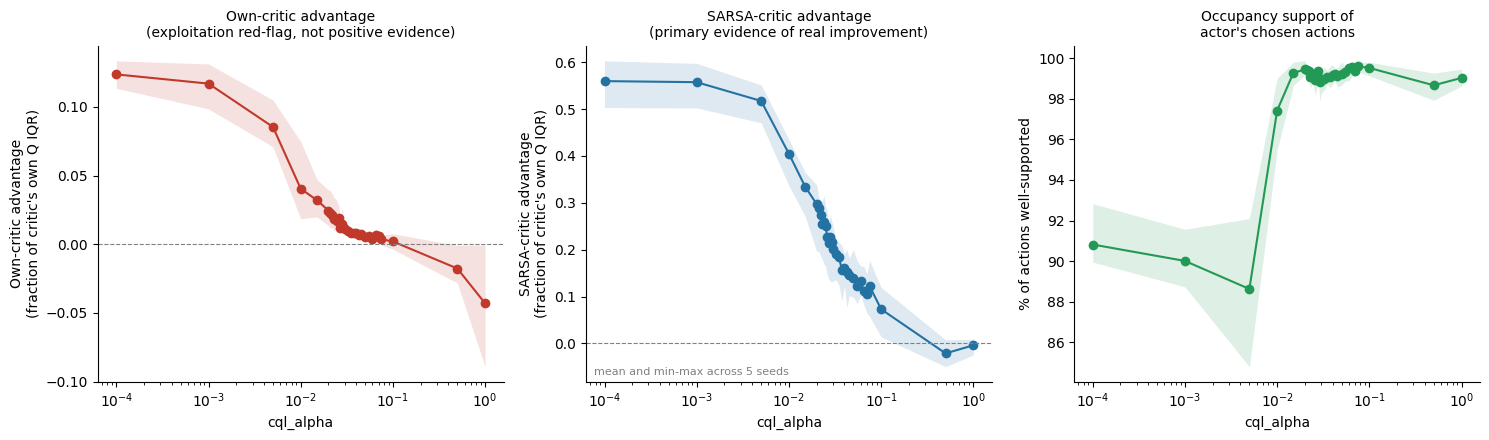

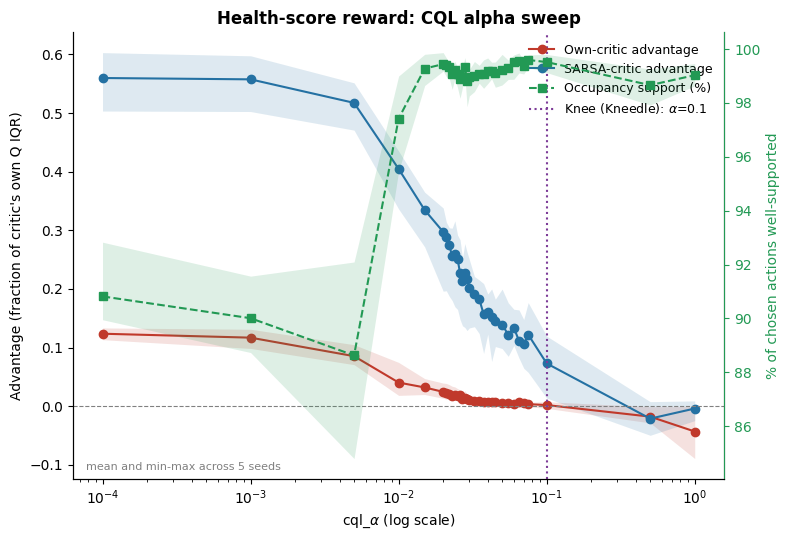

In [8]:
fig = eval_cql.plot_alpha_sweep(df_hs, normalized=True, log_scale=True,
        save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_health_score.png"))
fig = eval_cql.plot_combined_alpha_sweep(df_hs, normalized=True, log_scale=True,
        title="Health-score reward: CQL alpha sweep",
        save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_combined_health_score.png"))

,mean,std,n_seeds,n_seeds_positive,cv,worst_window_ratio,unstable
alpha,,,,,,,
0.0000,0.559821,0.037638,5,5,0.067232,1.004296,False
0.0001,0.559700,0.037039,5,5,0.066177,1.081891,False
0.0010,0.557426,0.034968,5,5,0.062732,1.377434,False
0.0050,0.517335,0.029700,5,5,0.057410,1.546236,False
0.0100,0.404684,0.040262,5,5,0.099491,1.546236,False
0.0150,0.334577,0.036683,5,5,0.109641,1.546236,False
0.0200,0.297295,0.057396,5,5,0.193062,1.361221,False
0.0210,0.287961,0.050980,5,5,0.177039,1.161884,False
0.0220,0.274371,0.048886,5,5,0.178175,1.126635,False


instability onset: 0.075


max_ratio,1.25,1.50,2.00,3.00,5.00
window,,,,,
3,0.0010,0.0050,0.075,0.075,0.075
4,0.0001,0.0010,0.070,0.070,0.070
5,0.0000,0.0001,0.065,0.065,0.065


Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/sarsa_stability_health_score.png


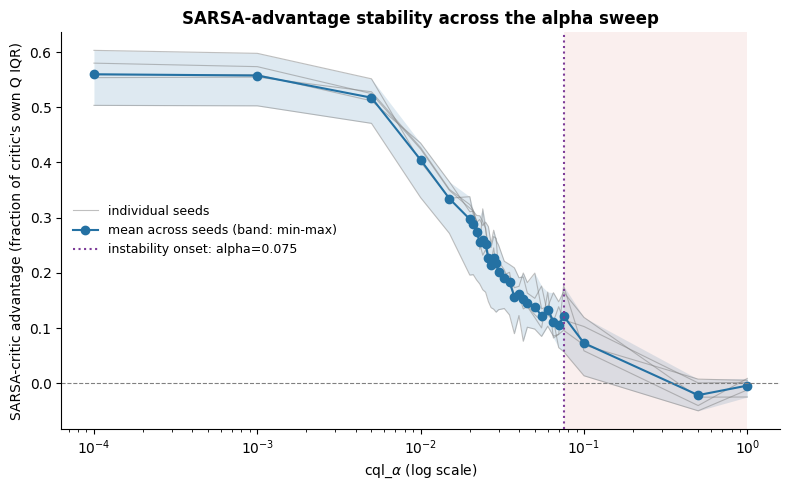

In [9]:
tab, onset = eval_cql.sarsa_stability(df_hs, window=3, max_ratio=2.0)
display(tab)
print("instability onset:", onset)
display(eval_cql.stability_sensitivity(df_hs))      # onset alpha across windows and thresholds

fig = eval_cql.plot_sarsa_stability(df_hs, onset, normalized=True, log_scale=True,
        save_path=os.path.join(cql_model_dir, "sarsa_stability_health_score.png"))

In [10]:
final_alpha, sel_info = eval_cql.select_final_alpha(df_hs, own_rule="any_seed", occupancy_margin=0.005)
display(sel_info)

alphas: 32
1. own-critic gate (any_seed): 28 pass; dropped [0.075, 0.1, 0.5, 1.0]
2. SARSA stability gate (window=3, max_ratio=2.0): onset=0.075; 28 survive both gates
3. occupancy: best survivor 99.56%, margin 0.50 points -> 18 tied: [0.015, 0.02, 0.021, 0.022, 0.023, 0.024, 0.025, 0.028, 0.035, 0.0375, 0.04, 0.0425, 0.045, 0.05, 0.055, 0.06, 0.065, 0.07]
4. highest SARSA advantage among the tied: alpha=0.015 (SARSA adv 0.3346, occupancy 99.28%)


,own_adv_mean,own_adv_min,pass_own,pass_stability,sarsa_adv,occupancy,survivor,tied_occupancy,selected
alpha,,,,,,,,,
0.0000,0.124245,0.110981,True,True,0.559821,0.921774,True,False,False
0.0001,0.123713,0.113550,True,True,0.559700,0.908195,True,False,False
0.0010,0.116996,0.098610,True,True,0.557426,0.900100,True,False,False
0.0050,0.085440,0.070966,True,True,0.517335,0.886292,True,False,False
0.0100,0.040449,0.018568,True,True,0.404684,0.974199,True,False,False
0.0150,0.032088,0.019984,True,True,0.334577,0.992772,True,True,True
0.0200,0.024556,0.013624,True,True,0.297295,0.994425,True,True,False
0.0210,0.022801,0.011870,True,True,0.287961,0.993957,True,True,False
0.0220,0.021078,0.012524,True,True,0.274371,0.993507,True,True,False


# Action distributions

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_fluid_health_score.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_at_clinician_zero_health_score.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_vaso_health_score.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/vaso_at_clinician_zero_health_score.png


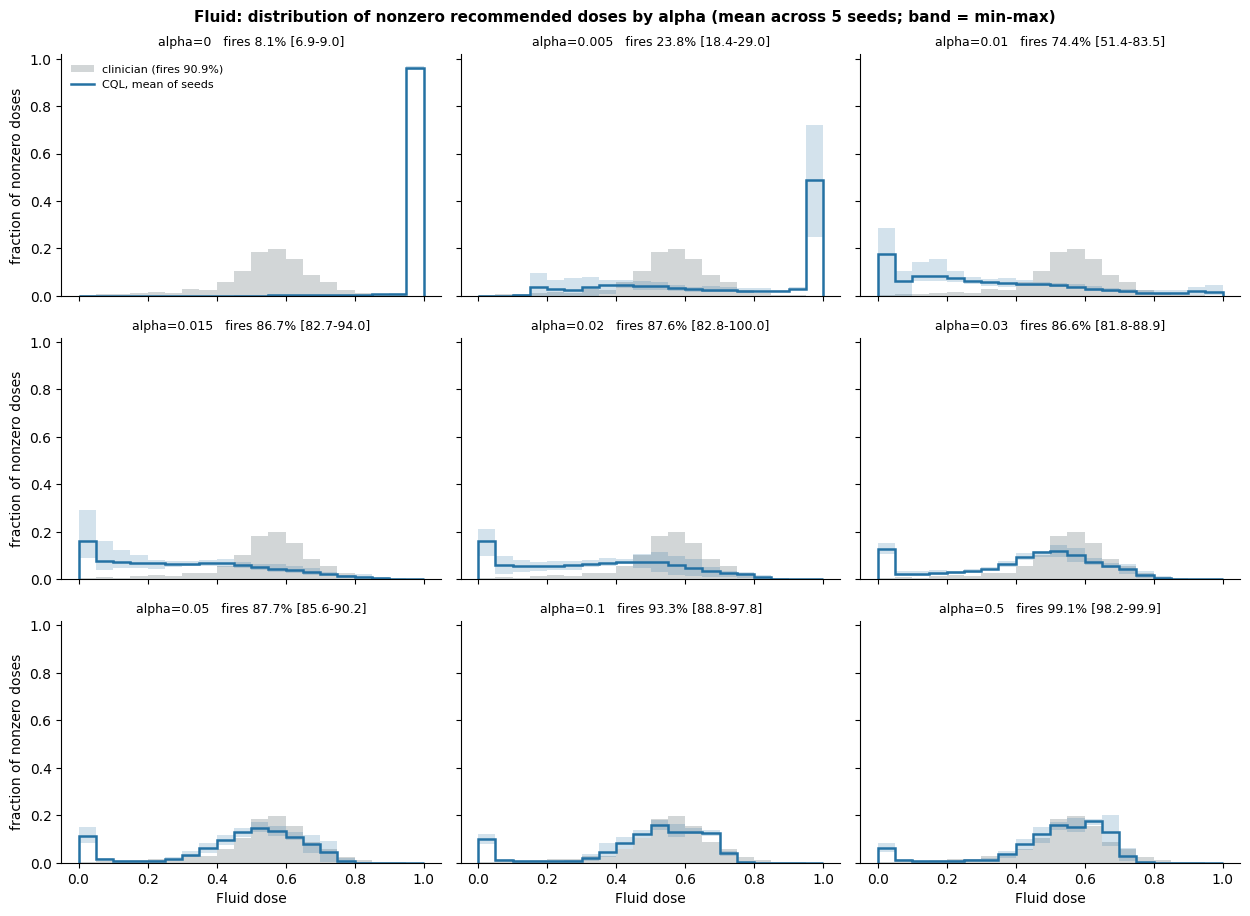

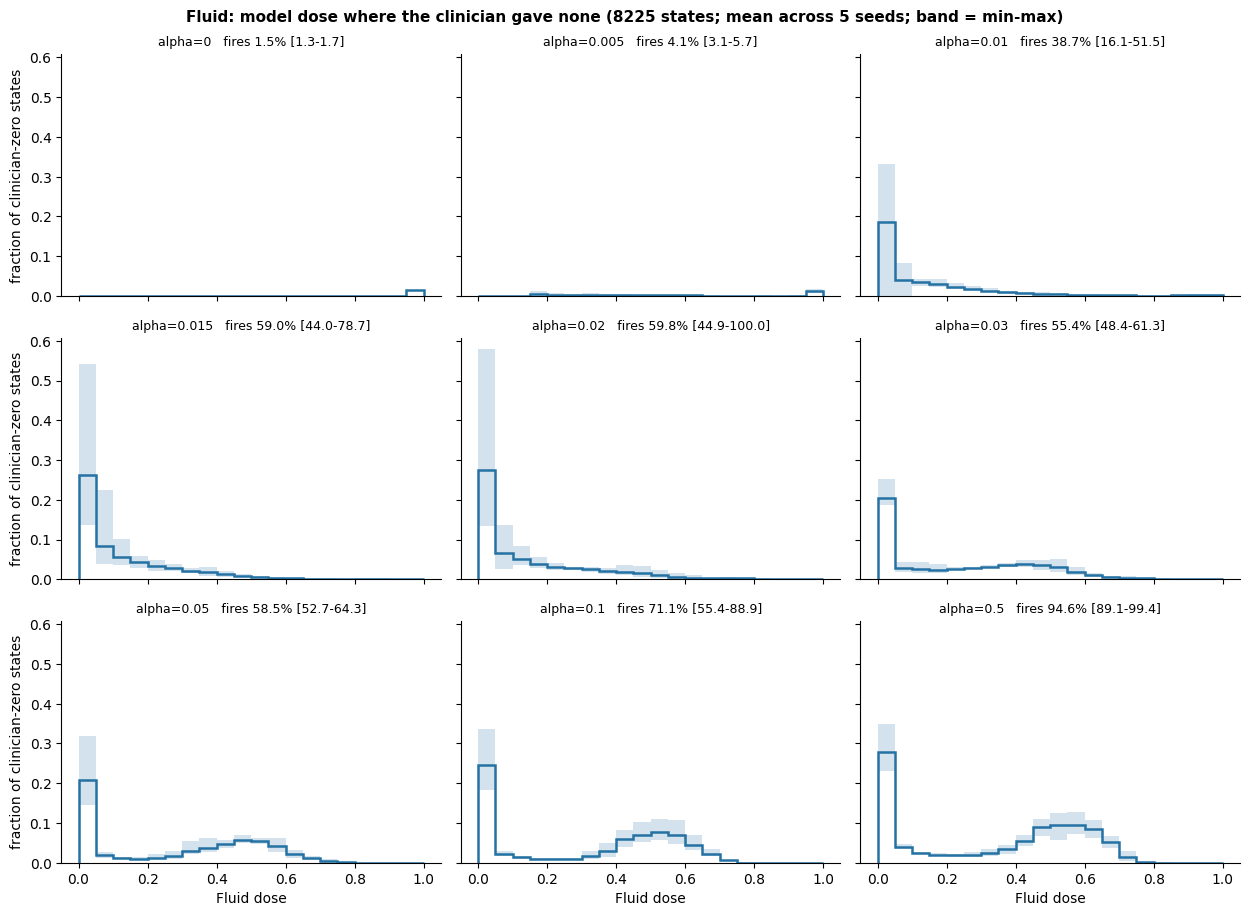

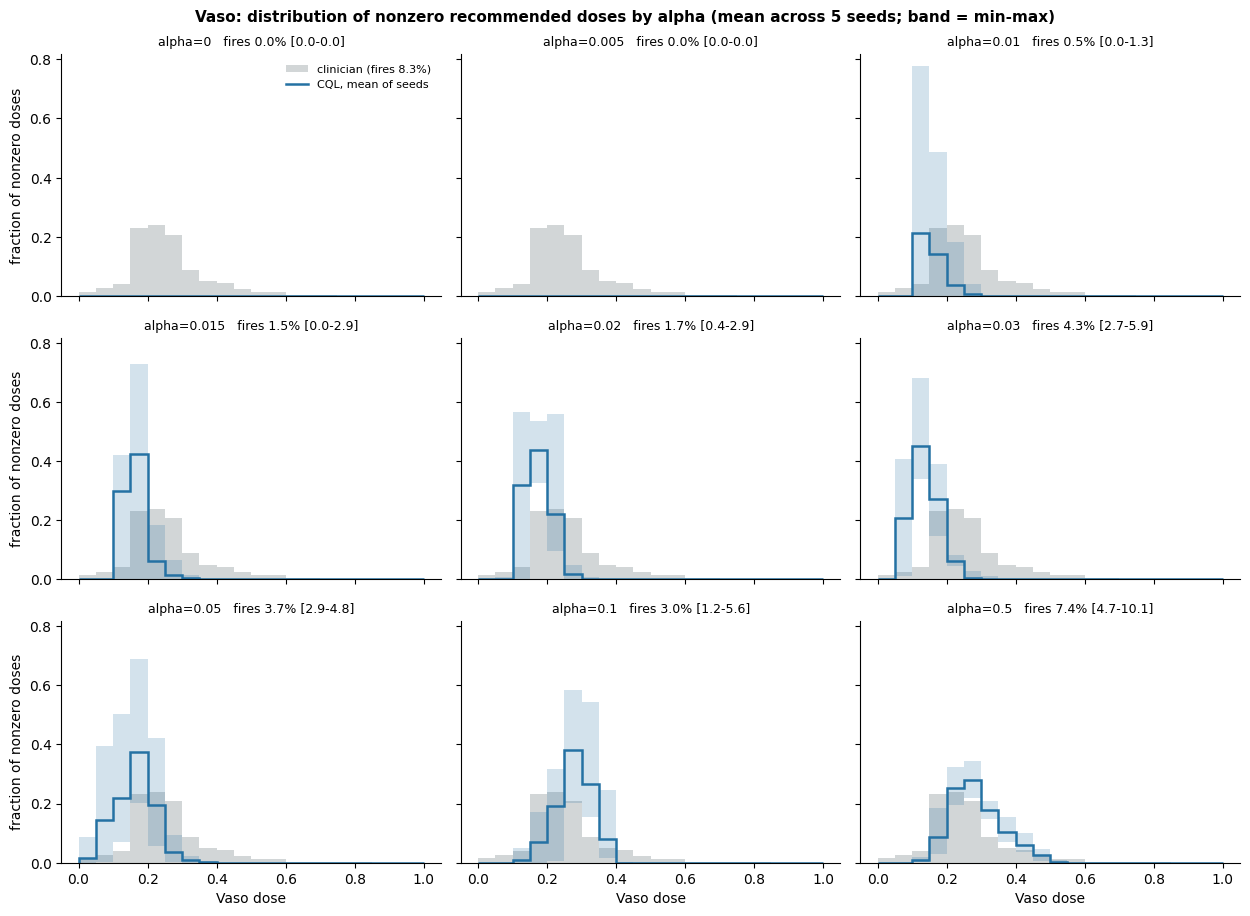

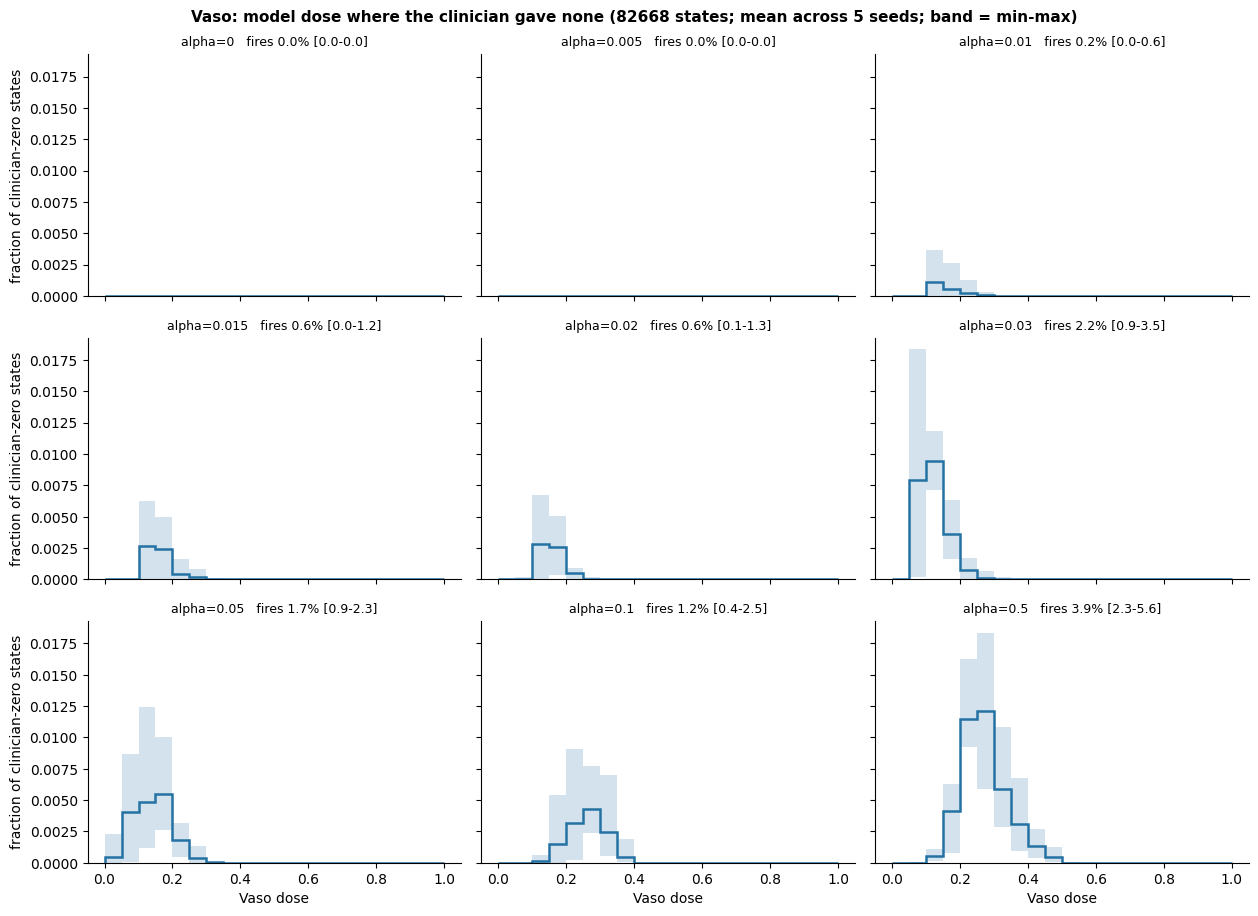

In [11]:
import src.rl.dose_histogram_by_alpha as dose_hist

actions_hs, clin_val = dose_hist.collect_actions(cql_hs_models, store, split="val")   # once; reused by all plots

show = [0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.1, 0.5]
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_histograms(actions_hs, clin_val, dim=dim, dim_name=name, alphas_to_show=show,
        save_path=os.path.join(cql_model_dir, f"dose_histogram_{name.lower()}_health_score.png"))
    dose_hist.plot_dose_histograms_at_clinician_zero(actions_hs, clin_val, dim=dim, dim_name=name, alphas_to_show=show,
        save_path=os.path.join(cql_model_dir, f"{name.lower()}_at_clinician_zero_health_score.png"))

Fluid {'fire_rate': 0.9087651965569261, 'w1': 0.0, 'low_share': 0.00346650066522636, 'high_share': 0.0030026731114284667, 'median_nz': 0.5589511394500732}


fire_rate                            w1                     low_share  \
           mean       min       max      mean       min       max      mean   
alpha                                                                         
0.015  0.867329  0.826715  0.940412  0.236940  0.185530  0.275302  0.160488   
0.020  0.875907  0.827613  1.000000  0.210674  0.124830  0.306850  0.160440   
0.025  0.876355  0.794336  1.000000  0.177046  0.130589  0.226390  0.148151   
0.030  0.865933  0.817797  0.888999  0.131249  0.099684  0.173037  0.128182   
0.035  0.865853  0.840059  0.886503  0.123429  0.087847  0.153255  0.120206   
0.050  0.876954  0.855921  0.901699  0.088159  0.055726  0.131955  0.110641   
0.100  0.932665  0.888278  0.978470  0.066102  0.042594  0.084291  0.099034   

                          high_share                     median_nz            \
            min       max       mean       min       max      mean       min   
alpha                                                                          
0.015  0.089046  0.291484   0.002873  0.000347  0.006373  0.287597  0.212508   
0.020  0.097252  0.212197   0.000094  0.000000  0.000445  0.342790  0.220710   
0.025  0.116285  0.180434   0.000020  0.000000  0.000056  0.405454  0.326024   
0.030  0.105208  0.154608   0.000017  0.000000  0.000050  0.463562  0.423050   
0.035  0.093949  0.134507   0.000000  0.000000  0.000000  0.470524  0.437903   
0.050  0.084167  0.150124   0.000000  0.000000  0.000000  0.507420  0.478780   
0.100  0.078698  0.120218   0.000000  0.000000  0.000000  0.526355  0.512810   

                 
            max  
alpha            
0.015  0.366331  
0.020  0.463741  
0.025  0.468352  
0.030  0.498596  
0.035  0.508058  
0.050  0.537666  
0.100  0.542992

Vaso {'fire_rate': 0.08301535185020854, 'w1': 0.0, 'low_share': 0.01469802244788883, 'high_share': 0.0, 'median_nz': 0.23191073536872864}


fire_rate                            w1                     low_share  \
           mean       min       max      mean       min       max      mean   
alpha                                                                         
0.015  0.015403  0.000000  0.028862  0.099462  0.088888  0.105645  0.000000   
0.020  0.016534  0.004248  0.028984  0.092858  0.072683  0.108399  0.000000   
0.025  0.031946  0.019511  0.043870  0.097356  0.057049  0.119585  0.000000   
0.030  0.043045  0.026777  0.058557  0.122248  0.112150  0.131580  0.000000   
0.035  0.043336  0.038002  0.046255  0.120356  0.104836  0.134824  0.000400   
0.050  0.036691  0.029018  0.048440  0.099191  0.068883  0.129759  0.017425   
0.100  0.030378  0.012002  0.056482  0.060676  0.040771  0.095389  0.000000   

                     high_share           median_nz                      
       min       max       mean  min  max      mean       min       max  
alpha                                                                    
0.015  0.0  0.000000        0.0  0.0  0.0  0.158456  0.154733  0.161317  
0.020  0.0  0.000000        0.0  0.0  0.0  0.167638  0.143999  0.206744  
0.025  0.0  0.000000        0.0  0.0  0.0  0.163548  0.140878  0.230760  
0.030  0.0  0.000000        0.0  0.0  0.0  0.129748  0.106752  0.145863  
0.035  0.0  0.002000        0.0  0.0  0.0  0.135431  0.114031  0.155565  
0.050  0.0  0.087123        0.0  0.0  0.0  0.158329  0.117818  0.199018  
0.100  0.0  0.000000        0.0  0.0  0.0  0.276811  0.251115  0.325312

seed,0,1,2,3,4
alpha,,,,,
0.020,0.128828,0.212197,0.097252,0.173566,0.190357
0.021,0.138945,0.225142,0.102215,0.161096,0.181376
0.022,0.130002,0.195769,0.101901,0.152929,0.168543
0.023,0.141168,0.152099,0.105660,0.103738,0.175342
0.024,0.133440,0.139808,0.103668,0.158555,0.169961
0.025,0.140621,0.158377,0.116285,0.145040,0.180434
0.026,0.160542,0.143336,0.114310,0.135076,0.196378
0.027,0.143700,0.151209,0.095148,0.105598,0.139696
0.028,0.121635,0.184877,0.100086,0.148838,0.166425


seed,0,1,2,3,4
alpha,,,,,
0.020,0.197376,0.306850,0.124830,0.213231,0.211081
0.021,0.206567,0.296342,0.135143,0.206134,0.220614
0.022,0.185501,0.275415,0.128299,0.193325,0.203952
0.023,0.192775,0.240014,0.125293,0.161738,0.206933
0.024,0.161327,0.216215,0.128108,0.211891,0.187957
0.025,0.159255,0.226390,0.130589,0.185039,0.183958
0.026,0.157640,0.209612,0.113123,0.167834,0.205866
0.027,0.132148,0.169245,0.111422,0.151767,0.150248
0.028,0.114236,0.238901,0.104480,0.176613,0.168183


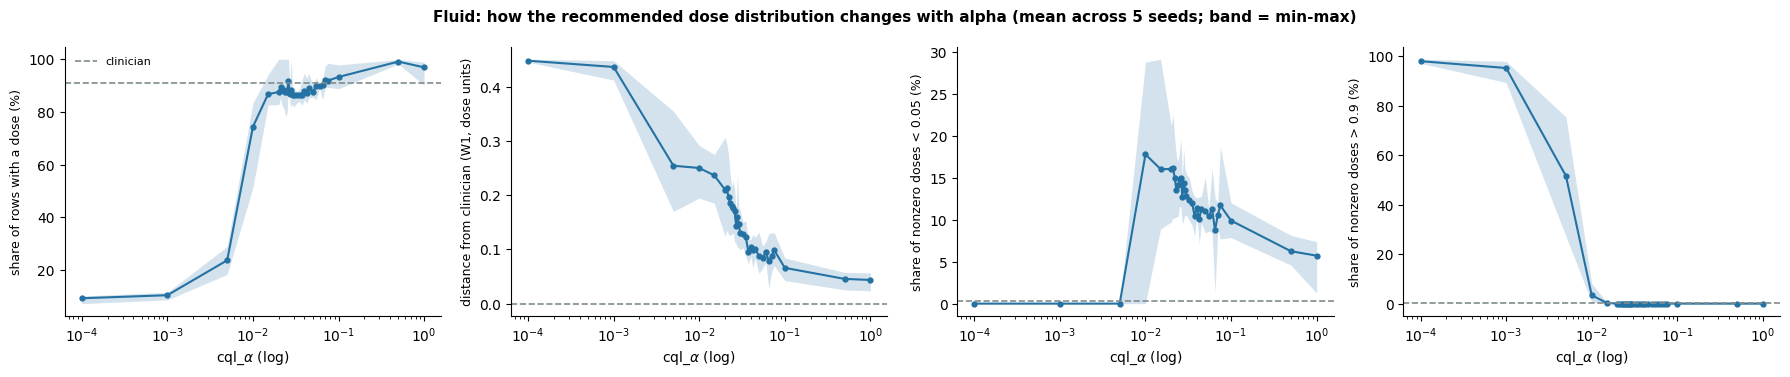

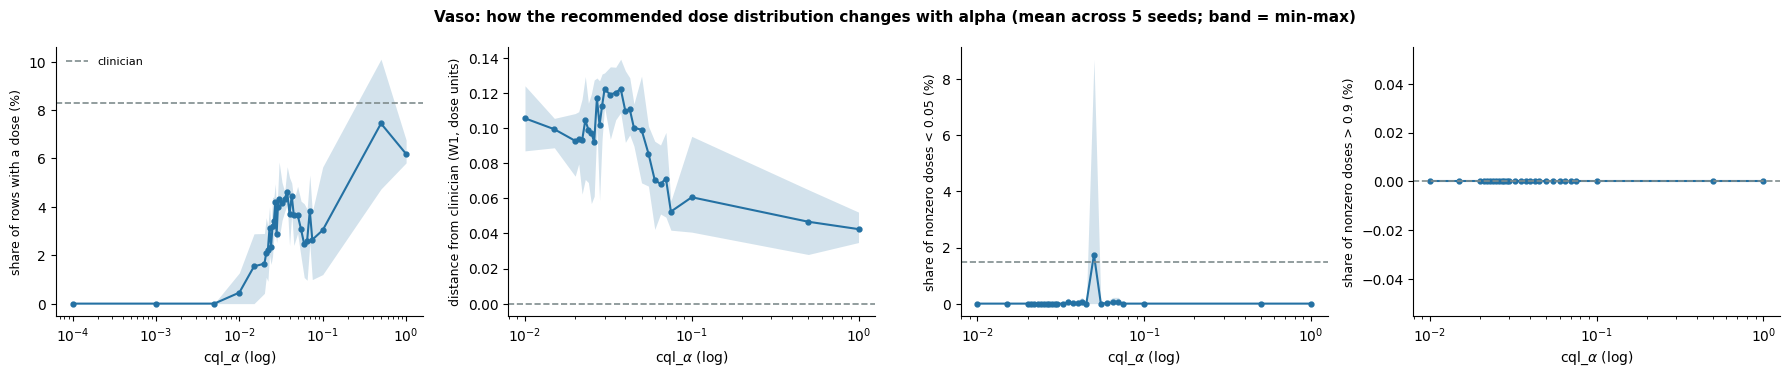

In [12]:
import importlib; importlib.reload(dose_hist)

dm = {name: dose_hist.dose_distribution_metrics(actions_hs, clin_val, dim)
      for dim, name in [(0, "Fluid"), (1, "Vaso")]}

# Seed-averaged table for the candidates, plus the clinician reference
cand = [0.015, 0.02, 0.025, 0.03, 0.035, 0.05, 0.1]
for name in dm:
    print(name, dose_hist.clinician_reference(clin_val, 0 if name == "Fluid" else 1))
    display(dose_hist.summarize_metrics(dm[name]).loc[cand])

# Metrics vs alpha (clinician as dashed line)
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_metrics(dm[name], clin_val, dim, name, save_path=None)

# Dense grid between 0.02 and 0.03: where does the low-dose tail disappear, and do all 5 seeds agree?
dense = dm["Fluid"][dm["Fluid"].alpha.between(0.02, 0.03)]
display(dense.pivot(index="alpha", columns="seed", values="low_share"))
display(dense.pivot(index="alpha", columns="seed", values="w1"))

,bin,n,fire_rate,mean_dose,median_nz,low_share,w1
0,0,18031,0.987078,0.569815,0.572926,0.000730,0.0
1,1,18030,0.963006,0.532074,0.560700,0.001325,0.0
2,2,18030,0.928841,0.500977,0.556382,0.002866,0.0
3,3,18030,0.894676,0.477604,0.554674,0.005579,0.0
4,4,18031,0.770229,0.398417,0.542683,0.007921,0.0


w1                             low_share                       \
bin        0      1      2      3      4         0      1      2      3   
alpha                                                                     
0.015  0.046  0.164  0.318  0.389  0.416     0.002  0.026  0.151  0.299   
0.020  0.048  0.131  0.278  0.360  0.394     0.002  0.022  0.146  0.314   
0.025  0.023  0.092  0.225  0.314  0.366     0.002  0.022  0.134  0.287   
0.030  0.028  0.056  0.160  0.250  0.310     0.003  0.021  0.109  0.253   
0.050  0.026  0.037  0.090  0.167  0.229     0.002  0.017  0.081  0.213   
0.100  0.024  0.029  0.052  0.115  0.191     0.001  0.013  0.062  0.164   

             fire_rate                              
bin        4         0      1      2      3      4  
alpha                                               
0.015  0.448     0.999  0.989  0.922  0.772  0.654  
0.020  0.453     1.000  0.995  0.950  0.801  0.634  
0.025  0.435     1.000  0.995  0.944  0.799  0.643  
0.030  0.391     1.000  0.995  0.947  0.796  0.592  
0.050  0.347     0.999  0.993  0.950  0.825  0.618  
0.100  0.310     1.000  0.997  0.978  0.923  0.765

,bin,n,fire_rate,mean_dose,median_nz,low_share,w1
0,0,18031,0.231047,0.064322,0.257637,0.005281,0.0
1,1,18030,0.097449,0.023246,0.221994,0.050085,0.0
2,2,18030,0.048475,0.010957,0.221994,0.000000,0.0
3,3,18030,0.028674,0.006406,0.221994,0.000000,0.0
4,4,18031,0.009428,0.001682,0.155214,0.000000,0.0


w1                             low_share                            \
bin        0      1      2      3      4         0    1      2      3      4   
alpha                                                                          
0.015  0.118  0.091  0.078  0.081  0.046       0.0  0.0  0.000  0.000  0.000   
0.020  0.108  0.087  0.082  0.094  0.059       0.0  0.0  0.000  0.000  0.000   
0.025  0.107  0.086  0.090  0.095  0.067       0.0  0.0  0.000  0.000  0.000   
0.030  0.127  0.111  0.119  0.125  0.085       0.0  0.0  0.000  0.000  0.000   
0.050  0.095  0.088  0.103  0.114  0.076       0.0  0.0  0.036  0.029  0.052   
0.100  0.055  0.088  0.058  0.054  0.064       0.0  0.0  0.000  0.000  0.000   

      fire_rate                              
bin           0      1      2      3      4  
alpha                                        
0.015     0.073  0.004  0.000  0.000  0.000  
0.020     0.074  0.006  0.001  0.001  0.001  
0.025     0.126  0.013  0.007  0.011  0.003  
0.030     0.135  0.021  0.019  0.028  0.012  
0.050     0.117  0.019  0.017  0.023  0.008  
0.100     0.116  0.023  0.007  0.005  0.001

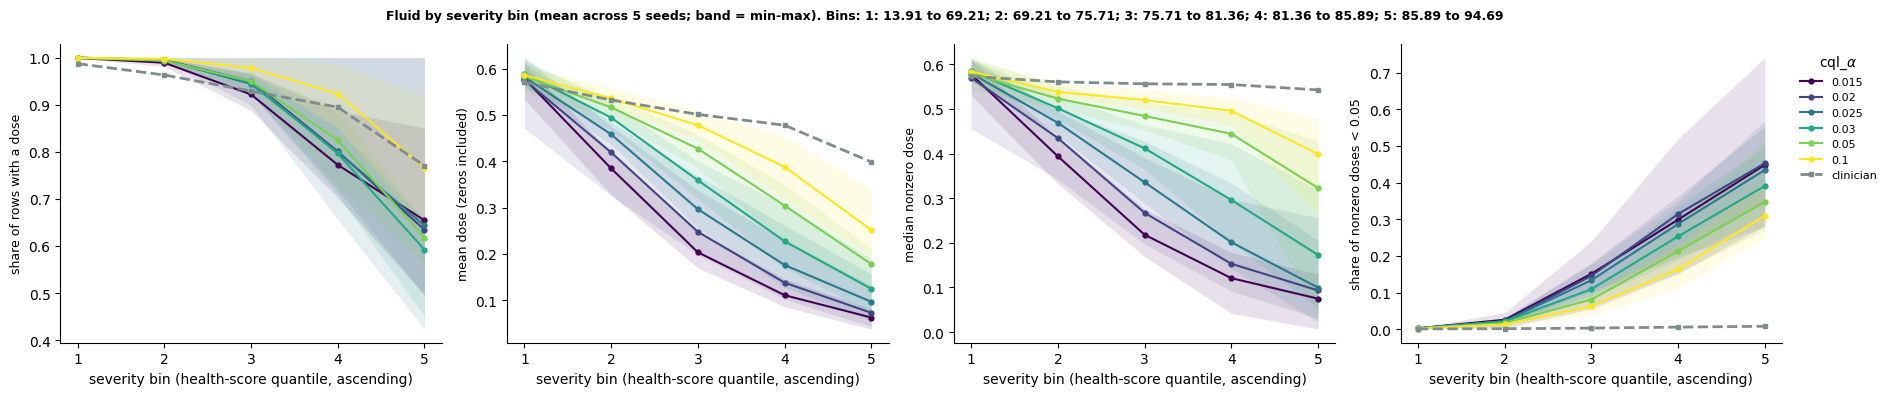

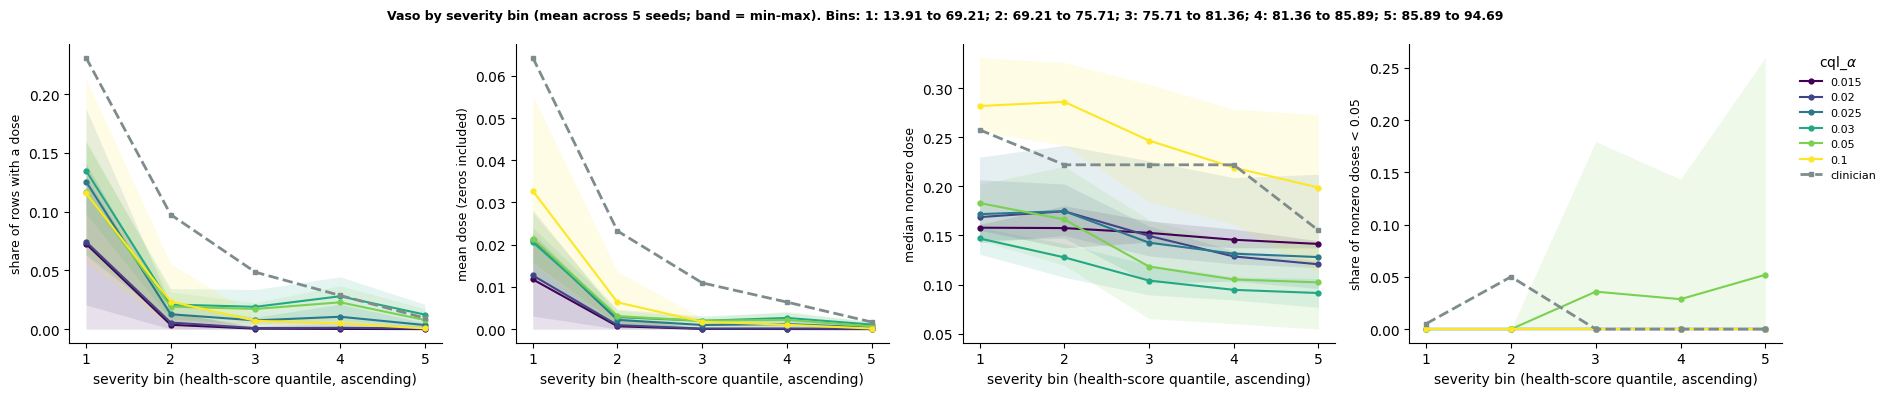

In [13]:
importlib.reload(dose_hist)

hs_val = dose_hist.collect_severity(cql_hs_models, store, split="val")

show = [0.015, 0.02, 0.025, 0.03, 0.05, 0.1]
sev = {}
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    sev[name] = dose_hist.dose_by_severity(actions_hs, clin_val, hs_val, dim, n_bins=5)
    df_s, clin_s, labels = sev[name]
    dose_hist.plot_dose_by_severity(df_s, clin_s, labels, name, show, save_path=None)

# Tables: clinician per bin, and seed-mean W1 / low share per alpha x bin for fluid
df_f, clin_f, labels = sev["Fluid"]
display(clin_f)
display(df_f[df_f.alpha.isin(show)].groupby(["alpha", "bin"])[["w1", "low_share", "fire_rate"]].mean().unstack("bin").round(3))

df_v, clin_v, labels = sev["Vaso"]
display(clin_v)
display(df_v[df_v.alpha.isin(show)].groupby(["alpha", "bin"])[["w1", "low_share", "fire_rate"]].mean().unstack("bin").round(3))

In [14]:
for name in ["Fluid", "Vaso"]:
    d = dm[name][dm[name].alpha.between(0.02, 0.04)]
    display(d.pivot(index="alpha", columns="seed", values="fire_rate").round(3))

seed,0,1,2,3,4
alpha,,,,,
0.0200,0.828,1.000,0.848,0.830,0.874
0.0210,0.852,1.000,0.863,0.874,0.875
0.0220,0.822,1.000,0.864,0.854,0.872
0.0230,0.815,1.000,0.865,0.875,0.858
0.0240,0.784,1.000,0.880,0.847,0.861
0.0250,0.794,1.000,0.895,0.862,0.830
0.0260,0.909,1.000,0.890,0.892,0.892
0.0270,0.874,0.884,0.903,0.835,0.847
0.0280,0.834,1.000,0.901,0.867,0.819


seed,0,1,2,3,4
alpha,,,,,
0.0200,0.004,0.008,0.019,0.029,0.022
0.0210,0.016,0.011,0.035,0.018,0.024
0.0220,0.009,0.021,0.026,0.023,0.032
0.0230,0.020,0.024,0.033,0.040,0.039
0.0240,0.026,0.021,0.030,0.016,0.023
0.0250,0.020,0.024,0.039,0.033,0.044
0.0260,0.029,0.028,0.044,0.029,0.042
0.0270,0.036,0.047,0.050,0.047,0.030
0.0280,0.037,0.025,0.025,0.030,0.027


In [15]:
import src.rl.alpha_candidate_table as cand
importlib.reload(cand)
gate = cand.degenerate_seed_gate(dm["Fluid"], dm["Vaso"])
limit = cand.max_eligible_alpha(df_hs)          # expect 0.07, the last alpha where every seed's own-critic advantage is positive
print("eligible up to:", limit, "| first clean alpha up to there:", cand.first_clean_alpha(gate, limit))

display(gate.loc[0.02:0.04])

cands = [0.015, 0.02, 0.025, 0.029, 0.03, 0.035, 0.05]
display(cand.candidate_table(df_hs, dm["Fluid"], dm["Vaso"], gate, cands).T)

eligible up to: 0.07 | first clean alpha up to there: 0.029


,max_fluid_fire,fluid_degenerate_seeds,min_vaso_fire,vaso_degenerate_seeds,clean
alpha,,,,,
0.0200,1.000000,1,0.004248,0,False
0.0210,1.000000,1,0.010859,0,False
0.0220,1.000000,1,0.009262,0,False
0.0230,1.000000,1,0.020044,0,False
0.0240,1.000000,1,0.016206,0,False
0.0250,1.000000,1,0.019511,0,False
0.0260,1.000000,1,0.028197,0,False
0.0270,0.903263,0,0.029750,0,True
0.0280,1.000000,1,0.025158,0,False


alpha,0.015,0.020,0.025,0.029,0.030,0.035,0.050
sarsa_adv_mean,0.335,0.297,0.252,0.217,0.201,0.183,0.139
sarsa_adv_min,0.272,0.196,0.165,0.129,0.133,0.124,0.098
own_adv>0 (seeds),5.000,5.000,5.000,5.000,5.000,5.000,5.000
occupancy_mean,0.993,0.994,0.991,0.988,0.990,0.991,0.992
occupancy_min,0.986,0.992,0.986,0.979,0.983,0.987,0.987
fluid_fire_mean,0.867,0.876,0.876,0.866,0.866,0.866,0.877
fluid_fire_max,0.940,1.000,1.000,0.894,0.889,0.887,0.902
fluid_w1,0.237,0.211,0.177,0.147,0.131,0.123,0.088
fluid_low_share,0.160,0.160,0.148,0.135,0.128,0.120,0.111
vaso_fire_mean,0.015,0.017,0.032,0.040,0.043,0.043,0.037


In [16]:
import json, datetime
from src.rl.evaluate_cql_alpha_sweep import _models_by_alpha

final_alpha = 0.03
by_alpha = _models_by_alpha(cql_hs_models)
key = min(by_alpha, key=lambda a: abs(a - final_alpha))
assert abs(key - final_alpha) < 1e-12 and sorted(by_alpha[key]) == [0, 1, 2, 3, 4]

selection = {
    "reward": "health_score_change_only",
    "selected_on": "val",
    "alpha": final_alpha,
    "run_dirs": {int(s): str(m.record.run_dir) for s, m in sorted(by_alpha[key].items())},
    "criteria_in_order": [
        "own-critic advantage > 0 in every seed (pre-specified)",
        "no collapsed fluid/vaso gate in any seed, from the chosen alpha up to the eligible limit (added post hoc, after inspecting dose distributions)",
        "occupancy reasonable (>= 0.979 in every seed; not discriminating)",
        "highest SARSA advantage among the remaining, then judged on clinician-likeness of dose distributions (post hoc)",
    ],
    "eligible_limit_alpha": limit,
    "first_clean_alpha": cand.first_clean_alpha(gate, limit),
    "date": datetime.date.today().isoformat(),
}
print(json.dumps(selection, indent=2))
with open(sel_path := f"{cql_hs_dir}/final_alpha_selection.json", "w") as f:   # or wherever you keep analysis outputs
    json.dump(selection, f, indent=2)
print("saved to", sel_path)

{
  "reward": "health_score_change_only",
  "selected_on": "val",
  "alpha": 0.03,
  "run_dirs": {
    "0": "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20261010_000650/unknown_cx3-20-2_20261010-002610_8a7398af",
    "1": "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20261010_000650/unknown_cx3-20-2_20261010-002826_096fb87f",
    "2": "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep/choc_cql_with_logprobs_intake-vis_single_h

# standard deviation

{'floor': 0.1353352832366127, 'ceil': 2.718281828459045}


,n_mean,std_mean,std_p05,std_p95,frac_floor_worst,frac_ceil_worst,gate_sat_low_worst,gate_sat_high_worst
alpha,,,,,,,,
0.000,1612.4,0.802,0.174,0.950,0.065,0.000,0.0,0.979
0.015,19572.6,0.848,0.268,2.276,0.074,0.230,0.0,1.000
0.020,20000.0,0.881,0.286,2.328,0.002,0.244,0.0,1.000
0.025,20000.0,0.903,0.284,2.367,0.001,0.268,0.0,1.000
0.029,20000.0,0.986,0.303,2.718,0.000,0.234,0.0,1.000
0.030,20000.0,0.975,0.302,2.718,0.000,0.257,0.0,1.000
0.035,20000.0,0.982,0.304,2.718,0.000,0.245,0.0,1.000
0.050,19760.8,0.931,0.304,2.718,0.003,0.224,0.0,1.000
0.100,20000.0,0.621,0.165,2.718,0.672,0.174,0.0,1.000


,n_mean,std_mean,std_p05,std_p95,frac_floor_worst,frac_ceil_worst,gate_sat_low_worst,gate_sat_high_worst
alpha,,,,,,,,
0.000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0.015,324.2,0.731,0.659,0.841,0.0,0.0,0.0,0.0
0.020,348.8,0.694,0.627,0.787,0.0,0.0,0.0,0.0
0.025,672.0,0.663,0.573,0.758,0.0,0.0,0.0,0.0
0.029,830.6,0.713,0.605,0.843,0.0,0.0,0.0,0.0
0.030,890.8,0.725,0.609,0.846,0.0,0.0,0.0,0.0
0.035,902.2,0.711,0.599,0.830,0.0,0.0,0.0,0.0
0.050,766.6,0.743,0.589,0.899,0.0,0.0,0.0,0.0
0.100,632.4,0.531,0.401,0.676,0.0,0.0,0.0,0.0


,alpha,seed,dim,n,std_mean,frac_floor,frac_ceil
73,0.005,3,Fluid,5555,0.500997,0.534653,0.052565
85,0.010,1,Fluid,10258,0.194194,0.702964,0.000000
593,0.100,3,Fluid,20000,0.474038,0.671950,0.089150
601,0.500,0,Fluid,20000,0.200375,0.894500,0.005950
605,0.500,1,Fluid,20000,0.159104,0.924350,0.000100
609,0.500,2,Fluid,20000,0.191157,0.882250,0.001950
613,0.500,3,Fluid,20000,0.178351,0.915700,0.001900
617,0.500,4,Fluid,20000,0.173256,0.925950,0.001350
621,1.000,0,Fluid,20000,0.186289,0.888050,0.000650
625,1.000,1,Fluid,20000,0.168155,0.913350,0.000650


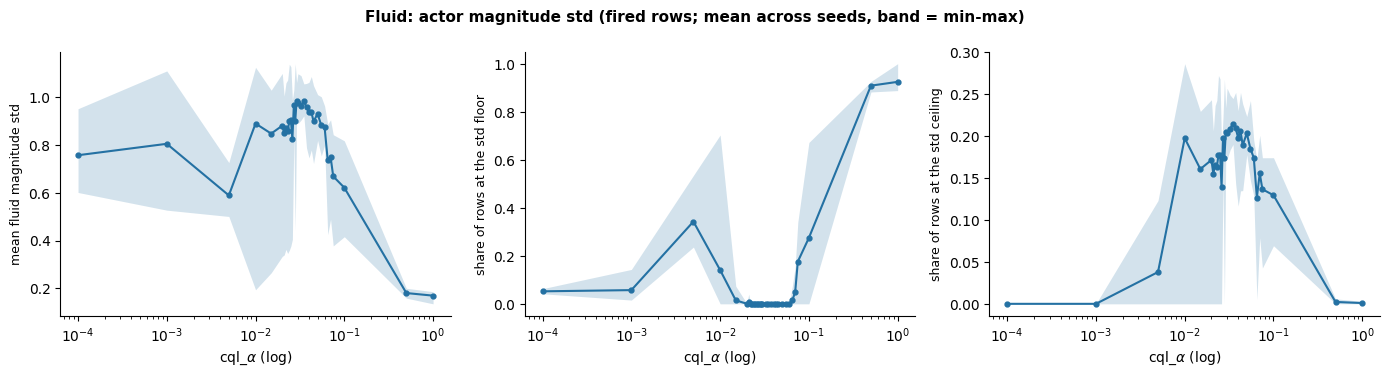

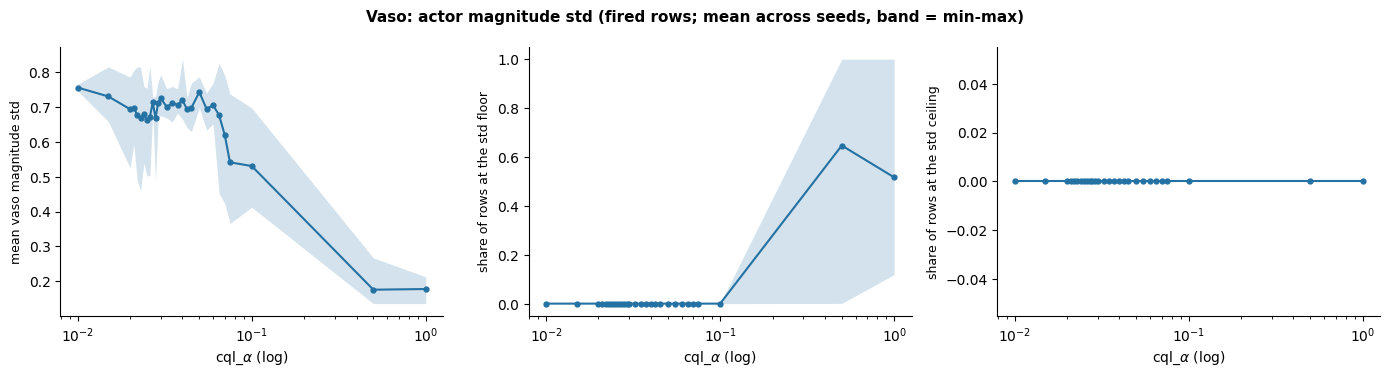

In [17]:
import src.rl.actor_std_check as stdchk
importlib.reload(stdchk)

import numpy as np
importlib.reload(stdchk)

std_hs = stdchk.actor_std_summary(cql_hs_models, store, split="val", bounds=(np.exp(-2), np.exp(1)))
print(std_hs[["floor", "ceil"]].iloc[0].to_dict())          # expect 0.135 and 2.718

for dim in ["Fluid", "Vaso"]:
    display(stdchk.summarize_std(std_hs, where="fired", dim=dim).loc[dim].loc[[0, 0.015, 0.02, 0.025, 0.029, 0.03, 0.035, 0.05, 0.1]].round(3))
    stdchk.plot_std_summary(std_hs, dim, where="fired", save_path=None)

display(stdchk.flag_stuck(std_hs, where="fired"))     # runs with >50% of fired rows at floor or ceiling

# final model

Final-model selection: CQL α sweep (health-score reward)

What was compared. 32 α values × 5 seeds. Everything below is on the validation split; the test split played no part in selection.

The rule (frozen).

Eligible range: α below the first value at which any seed’s own-critic advantage is ≤ 0. This is α ≤ 0.07 here; the first failure is 0.075.
Acceptable: support ≥ 0.95 in every seed, and no degenerate seed (fluid fire rate < 0.99, vaso fire rate > 0.001). This must hold at that α and at every larger eligible α.
Choose the acceptable α with the highest mean SARSA advantage. Ties go to the lower α.

Result: α = 0.029 (select_final_alpha_rule). The five seeds at this α are the final models.

	α = 0.029
SARSA advantage, normalised: mean (worst seed)	0.217 (0.129)
Own-critic advantage > 0	5/5 seeds
Support: mean (worst seed)	0.988 (0.979)
Fluid fire rate: mean (max) vs clinician 0.909	0.866 (0.894)
Vaso fire rate: mean (min) vs clinician 0.083	0.040 (0.031)
Fluid W1 to clinician (nonzero doses)	0.147

What was pre-specified and what was not.

A first cascade (own-critic advantage > 0, SARSA stability gate, support, advantage) selected α = 0.015.
Dose distributions at 0.015–0.02 showed many very low fluid doses, and individual seeds had collapsed gates: a seed whose fluid gate fired on 100% of rows at α = 0.020–0.026 and 0.028, and a seed that never gave vasopressors at α = 0.015.
The degenerate-policy requirement and the “from this α upward” requirement were added after seeing those results. They are stated above as a generic rule so the choice does not depend on visual judgement.
The rule is now frozen and applied unchanged to the terminal-reward models.

Descriptive findings (not selection criteria).

SARSA advantage falls monotonically with α (0.56 at α = 0, 0.335 at 0.015, 0.201 at 0.03, 0.139 at 0.05, about 0 at ≥ 0.5).
Support is saturated (≥ 0.979 at every candidate), so it does not discriminate.
Fluid doses become more clinician-like as α rises (W1 0.237 at 0.015, 0.147 at 0.029, 0.088 at 0.05), with no knee.
The remaining difference is concentrated in healthier patients. At α = 0.03, 25% (bin 4) and 39% (bin 5) of nonzero fluid doses are below 0.05 in the two highest health-score bins, against under 1% for the clinician. The clinician varies mainly whether fluid is given, not how much; the policies also lower the dose in healthier patients.
Vasopressors are under-prescribed relative to the clinician (fire rate about 0.04 against 0.083) at all candidate α, which was expected and which higher α did not fix.
Actor magnitude-std check: no policy at 0.015–0.05 has more than half its fired states at the log-std clamp. In the worst seed about a quarter of fluid fired states sit at the ceiling at every α from 0.015 to 0.05.

Sensitivity and limitations.

0.029 and 0.030 are indistinguishable (mean advantage 0.217 vs 0.201, worst seed 0.129 vs 0.133). An optional neighbour check (neighbour_check=True) selects 0.030.
The thresholds (0.95, 0.99, 0.001) are generic round numbers, not tuned; the support threshold never binds.
A single degenerate seed at any larger eligible α pushes the choice higher; a finer grid can only make the rule stricter.
WIS has not yet been run. Off-policy value estimates are therefore not part of this selection.

In [18]:
final_alpha, rule_table = cand.select_final_alpha_rule(df_hs, dm["Fluid"], dm["Vaso"])
final_alpha_margin, rule_table_margin = cand.select_final_alpha_rule(df_hs, dm["Fluid"], dm["Vaso"], neighbour_check=True)

print(f"Final alpha (rule):                       {final_alpha}")
print(f"Final alpha (with neighbour_check=True):  {final_alpha_margin}")

Final alpha (rule):                       0.029
Final alpha (with neighbour_check=True):  0.03


# for paper:
Selection of the CQL regularisation strength. We trained CQL policies over a sweep of 32 values of the conservatism coefficient α (0 to 1.0), with five seeds each (160 policies). Seed k of each policy was trained on the states from Dynamic-DeepHit seed k, and each policy was paired with the independent SARSA critic of the same seed. All selection was done on the validation set. For each policy we computed the advantage of the policy’s action over the clinician’s action under its own critic and under the independent SARSA critic, normalised by the interquartile range of that critic’s Q-values under clinician actions. We also computed state-action support: the fraction of validation states whose chosen (severity, fluid, vasopressor) bin had at least 10 training occurrences. The final α was the one with the highest mean SARSA advantage among the values that satisfied three requirements. First, own-critic advantage had to be positive in every seed, which defined the eligible range (α ≤ 0.07). Second, support had to be at least 0.95 in every seed. Third, no seed could have a degenerate policy, meaning fluid given at ≥99% of states or vasopressors given at ≤0.1% of states. The second and third requirements had to hold at that α and at every larger eligible α. This selected α = 0.029. The five seeds at this α were used as the final models without retraining and were then evaluated once on the held-out test set. The degenerate-policy requirement was added after inspecting validation-set dose distributions (see Supplement); the rule was then frozen and applied unchanged to the terminal-reward sweep.


# test set evaluation

In [19]:
# 1) A store that also builds the test split; restrict the CQL models to the chosen alpha
store_test = D.DataStore(keep=("train", "val", "test"))
final_cql = {k: v for k, v in cql_hs_models.items()
             if any(abs(m.record.get("cql_alpha") - final_alpha) < 1e-12 for m in v.values())}
assert len(final_cql) == 1 and len(next(iter(final_cql.values()))) == 5

# 2) Seed pairing / row alignment on test
procs = store_test.processors(final_cql, split="test")
display(D.check_rows_aligned(next(iter(procs.values()))))

# 3) Advantages and occupancy on test (same function, split="test")
df_test = eval_cql.run_alpha_sweep_analysis(final_cql, sarsa_hs_models, store_test, split="test", n_severity_bins=200)
display(df_test.round(3))
display(eval_cql.summarize_by_alpha(df_test).T)

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train, val)


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score rewa

,n_rows,same_index_ptr,same_actions,same_health_score,same_rewards,same_states
0,116662,True,True,True,True,True
1,116662,True,True,True,True,False
2,116662,True,True,True,True,False
3,116662,True,True,True,True,False
4,116662,True,True,True,True,False


alpha=0.029      (deterministic, test, 5 seeds)  own_norm=+0.0148  sarsa_norm=+0.2238 [+0.1363, +0.2644]  occupancy=98.5%  (1.8s)


,alpha,seed,own_adv,own_adv_norm,sarsa_adv,sarsa_adv_norm,occupancy_frac,own_q_iqr,sarsa_q_iqr,n_rows
0,0.029,0,0.034,0.014,0.144,0.229,0.987,2.447,0.628,116662
1,0.029,1,0.031,0.014,0.143,0.235,0.984,2.112,0.611,116662
2,0.029,2,0.025,0.009,0.089,0.136,0.991,2.784,0.651,116662
3,0.029,3,0.033,0.016,0.148,0.255,0.989,2.119,0.583,116662
4,0.029,4,0.038,0.021,0.169,0.264,0.974,1.789,0.640,116662


alpha                   0.029
own_adv        mean  0.032080
               min   0.025105
               max   0.037553
               std   0.004633
own_adv_norm   mean  0.014804
               min   0.009016
               max   0.020987
               std   0.004282
sarsa_adv      mean  0.138707
               min   0.088647
               max   0.169280
               std   0.029931
sarsa_adv_norm mean  0.223841
               min   0.136260
               max   0.264423
               std   0.051052
occupancy_frac mean  0.984866
               min   0.973985
               max   0.990657
               std   0.006569
n_seeds              5.000000

fire_rate                            w1                     low_share  \
           mean       min       max      mean       min       max      mean   
alpha                                                                         
0.029   0.86904  0.854357  0.884367  0.157671  0.117298  0.181725  0.143394   

                          high_share           median_nz                      
            min       max       mean  min  max      mean       min       max  
alpha                                                                         
0.029  0.107093  0.165971        0.0  0.0  0.0  0.430815  0.398822  0.473776

fire_rate                           w1                     low_share  \
           mean      min       max      mean       min       max      mean   
alpha                                                                        
0.029  0.053406  0.04663  0.061657  0.121524  0.105205  0.137171       0.0   

                high_share           median_nz                      
       min  max       mean  min  max      mean       min       max  
alpha                                                               
0.029  0.0  0.0        0.0  0.0  0.0  0.155514  0.137561  0.174685

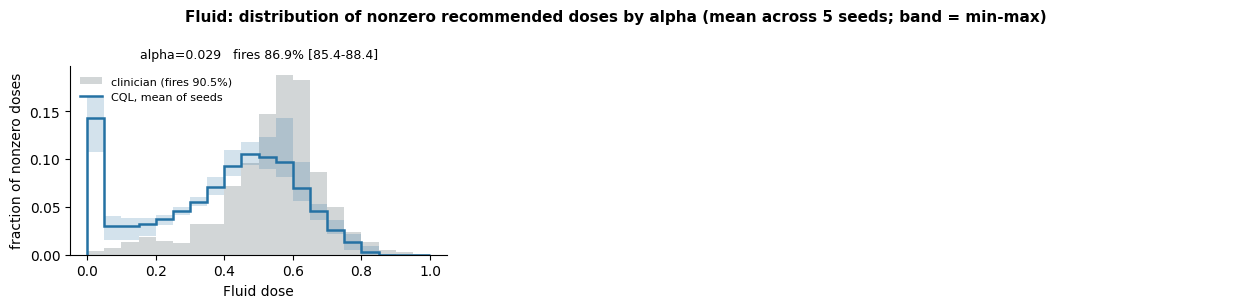

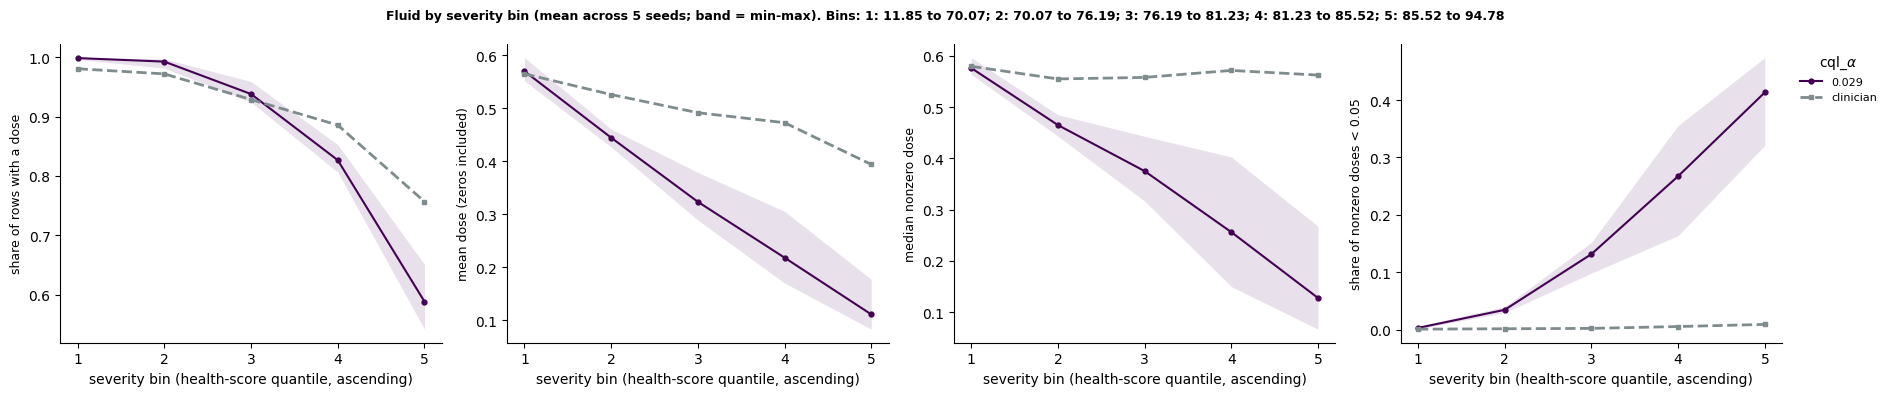

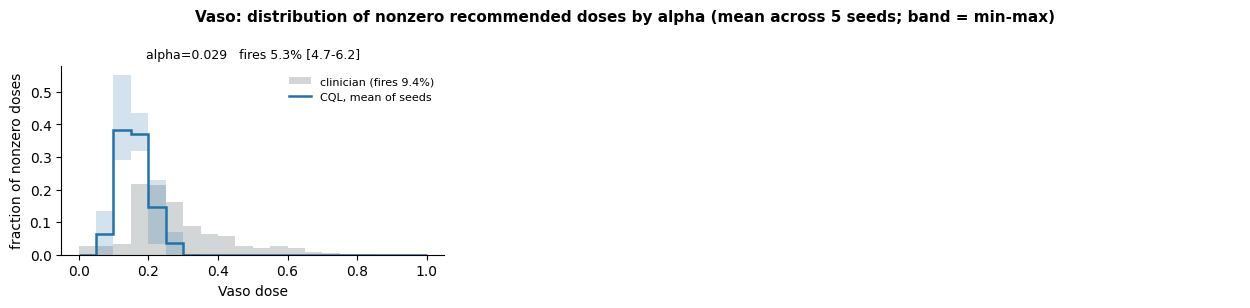

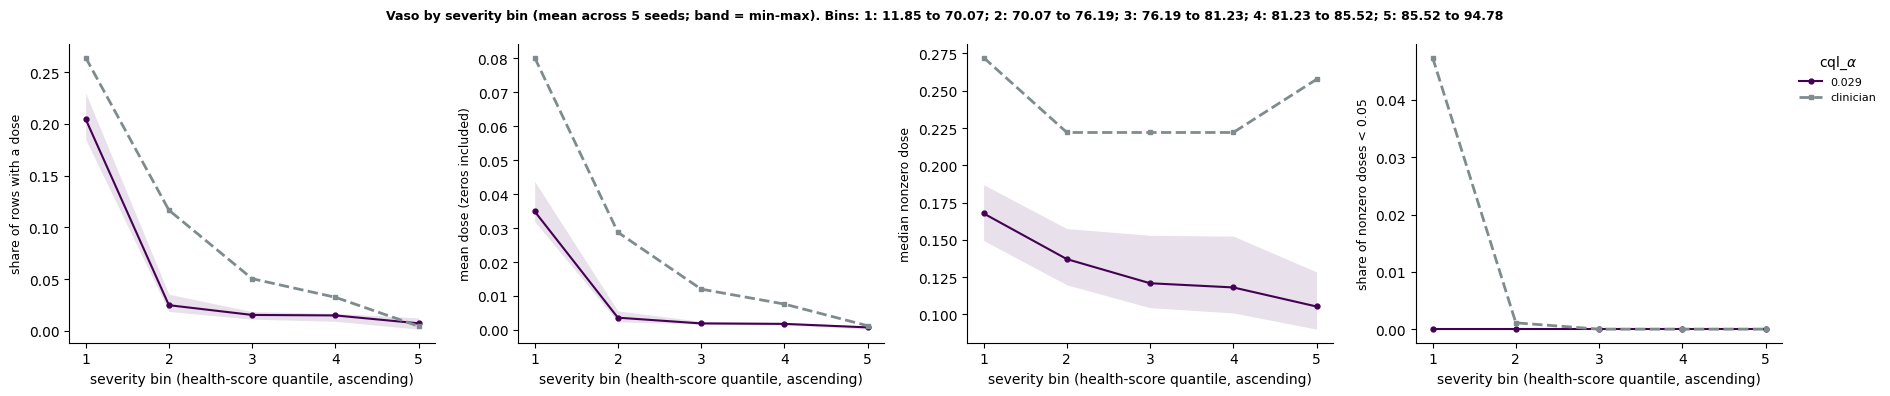

In [20]:
actions_t, clin_t = dose_hist.collect_actions(final_cql, store_test, split="test")
hs_t = dose_hist.collect_severity(final_cql, store_test, split="test")
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_histograms(actions_t, clin_t, dim=dim, dim_name=name, save_path=None)
    display(dose_hist.summarize_metrics(dose_hist.dose_distribution_metrics(actions_t, clin_t, dim)))
    df_s, clin_s, labels = dose_hist.dose_by_severity(actions_t, clin_t, hs_t, dim, n_bins=5)
    dose_hist.plot_dose_by_severity(df_s, clin_s, labels, name, [final_alpha], save_path=None)

# load terminal models

In [25]:
importlib.reload(eval_cql); importlib.reload(dose_hist); importlib.reload(cand); importlib.reload(stdchk)

term_study = R.make_study(cql_term_dir, group_by=("cql_alpha",), name="cql_terminal_alpha_sweep")
sarsa_term_study = R.make_study(sarsa_term_dir, name="sarsa_terminal_five_seeds")
cql_term_models = M.load_study_models(term_study)
sarsa_term_models = M.load_study_models(sarsa_term_study)

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/terminal_only/alpha_sweep:
    vaso_reward_coefficient: saved=0.01 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/terminal_only/

In [24]:
for name, st in [("SARSA terminal", sarsa_term_study), ("CQL terminal", term_study), ("SARSA health score", sarsa_hs_study)]:
    rec = st.runs()[0]
    cm = R._load_pickle(rec.config_path) if rec.config_path else None
    dc = (getattr(cm, "data_config", {}) or {}) if cm is not None else {}
    print("==", name, "|", rec.run_dir)
    print("    data_config keys:", sorted(dc))
    for k, v in dc.items():
        if isinstance(v, str) and ("/" in v or "seed" in k.lower()):
            print(f"      {k}: {v}")
    print("    identity:", rec.data_identity)

== SARSA terminal | /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/terminal_only/five_seeds/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-163424_71f56fa6
    data_config keys: ['actions', 'age_stay_ids_path', 'age_stays_dir', 'cohort', 'cohort_dir', 'cohort_stay_ids_path', 'features_to_use_path', 'model_type', 'prediction_type', 'proportion_w_data', 'reward_path', 'shard_dir', 'unit', 'unit_stay_ids_path', 'use_behavior_cloning_latents', 'use_reward', 'use_terminal_reward']
      features_to_use_path: /rds/general/user/jormond/home/projects/ai_clinician/code/choc_code/dataframes/features_to_use.csv
      shard_dir: combined_data/hourly_all_patients
      reward_path: /rds/general/user/jormond/home/projects/ai_clinician/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_4

# run terminal sweep

In [27]:
df_term = eval_cql.run_alpha_sweep_analysis(cql_term_models, sarsa_term_models, store, n_severity_bins=200)
display(eval_cql.summarize_by_alpha(df_term))

alpha=0          (deterministic, val, 5 seeds)  own_norm=+0.0726  sarsa_norm=+0.0526 [-0.0098, +0.0875]  occupancy=0.0%  (1.6s)
alpha=0.0001     (deterministic, val, 5 seeds)  own_norm=+0.0629  sarsa_norm=+0.0560 [-0.0097, +0.0955]  occupancy=27.2%  (0.9s)
alpha=0.001      (deterministic, val, 5 seeds)  own_norm=+0.0437  sarsa_norm=+0.0484 [+0.0319, +0.0647]  occupancy=75.5%  (0.9s)
alpha=0.005      (deterministic, val, 5 seeds)  own_norm=+0.0314  sarsa_norm=+0.0309 [-0.0075, +0.0503]  occupancy=64.0%  (0.9s)
alpha=0.01       (deterministic, val, 5 seeds)  own_norm=+0.0355  sarsa_norm=+0.0342 [+0.0236, +0.0446]  occupancy=74.3%  (0.9s)
alpha=0.015      (deterministic, val, 5 seeds)  own_norm=+0.0330  sarsa_norm=+0.0313 [+0.0231, +0.0400]  occupancy=70.8%  (0.9s)
alpha=0.02       (deterministic, val, 5 seeds)  own_norm=+0.0303  sarsa_norm=+0.0299 [+0.0227, +0.0384]  occupancy=67.5%  (0.9s)
alpha=0.021      (deterministic, val, 5 seeds)  own_norm=+0.0280  sarsa_norm=+0.0295 [+0.0223, +0.

own_adv                               own_adv_norm            \
            mean       min       max       std         mean       min   
alpha                                                                   
0.0000  0.262735  0.157432  0.336553  0.068672     0.072631  0.042056   
0.0001  0.227633  0.154253  0.281877  0.054226     0.062888  0.041199   
0.0010  0.158288  0.115629  0.176467  0.024513     0.043663  0.030899   
0.0050  0.112957 -0.032252  0.153684  0.081289     0.031388 -0.008623   
0.0100  0.128723  0.117473  0.155234  0.016154     0.035544  0.032164   
0.0150  0.119580  0.103677  0.140871  0.016789     0.033030  0.028512   
0.0200  0.110764  0.088235  0.134007  0.018150     0.030350  0.024158   
0.0210  0.102344  0.088040  0.113422  0.009301     0.028008  0.024143   
0.0220  0.101039  0.087595  0.109543  0.008618     0.027663  0.024015   
0.0230  0.098309  0.083738  0.112389  0.010217     0.026873  0.022939   
0.0240  0.096989  0.083847  0.108238  0.008686     0.026524  0.022998   
0.0250  0.095415  0.083930  0.111272  0.010010     0.026089  0.023029   
0.0260  0.095193  0.083594  0.111330  0.010136     0.026009  0.022935   
0.0270  0.093864  0.082605  0.114440  0.012105     0.025637  0.022660   
0.0280  0.089853  0.080652  0.095723  0.005653     0.024507  0.022123   
0.0290  0.087945  0.079432  0.094798  0.005588     0.023978  0.021765   
0.0300  0.086933  0.078526  0.089818  0.004736     0.023724  0.021554   
0.0325  0.083148  0.076110  0.090418  0.005400     0.022670  0.020884   
0.0350  0.081825  0.075243  0.090101  0.005438     0.022303  0.020617   
0.0375  0.078674  0.072304  0.087954  0.005838     0.021443  0.019804   
0.0400  0.075375  0.070300  0.084207  0.005643     0.020544  0.019099   
0.0425  0.072500  0.067759  0.081176  0.005560     0.019762  0.018400   
0.0450  0.070877  0.065324  0.080037  0.005820     0.019320  0.017739   
0.0500  0.068360  0.063082  0.079656  0.006643     0.018688  0.017292   
0.0550  0.065329  0.060320  0.075321  0.005794     0.017876  0.016535   
0.0600  0.062226  0.056923  0.073176  0.006386     0.017017  0.015608   
0.0650  0.060053  0.054699  0.065943  0.004267     0.016457  0.014995   
0.0700  0.058729  0.052587  0.064590  0.005177     0.016101  0.014424   
0.0750  0.058271  0.051326  0.064395  0.005719     0.015984  0.014077   
0.1000  0.055656  0.046217  0.065375  0.007012     0.015279  0.012702   
0.5000  0.063544  0.055902  0.071398  0.005663     0.018626  0.016017   
1.0000 -0.138958 -0.956610  0.070740  0.457101    -0.046101 -0.310098   

                           sarsa_adv            ...           sarsa_adv_norm  \
             max       std      mean       min  ...       std           mean   
alpha                                           ...                            
0.0000  0.097692  0.020427  0.193460 -0.037339  ...  0.150368       0.052637   
0.0001  0.081781  0.016233  0.205840 -0.036903  ...  0.157321       0.055953   
0.0010  0.049417  0.007550  0.178465  0.115904  ...  0.045326       0.048421   
0.0050  0.042698  0.022406  0.114624 -0.027356  ...  0.083018       0.030877   
0.0100  0.045082  0.005458  0.126461  0.086012  ...  0.033196       0.034234   
0.0150  0.041017  0.005322  0.115585  0.084217  ...  0.024178       0.031336   
0.0200  0.035961  0.005172  0.110314  0.082585  ...  0.023227       0.029916   
0.0210  0.030497  0.002562  0.108788  0.081013  ...  0.022612       0.029481   
0.0220  0.030664  0.002566  0.107314  0.082546  ...  0.020390       0.029097   
0.0230  0.029668  0.002535  0.104707  0.081170  ...  0.020593       0.028389   
0.0240  0.028554  0.002222  0.104942  0.080604  ...  0.021795       0.028457   
0.0250  0.029363  0.002497  0.105154  0.082443  ...  0.020781       0.028503   
0.0260  0.029373  0.002330  0.102827  0.080931  ...  0.019775       0.027884   
0.0270  0.030195  0.002841  0.102888  0.081503  ...  0.018428       0.027891   
0.0280  0.025534  0.001371  0.100382  0.077433  ...  0.019261       0.027209   
0.0290  0.025

Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_terminal.png
Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_terminal.png


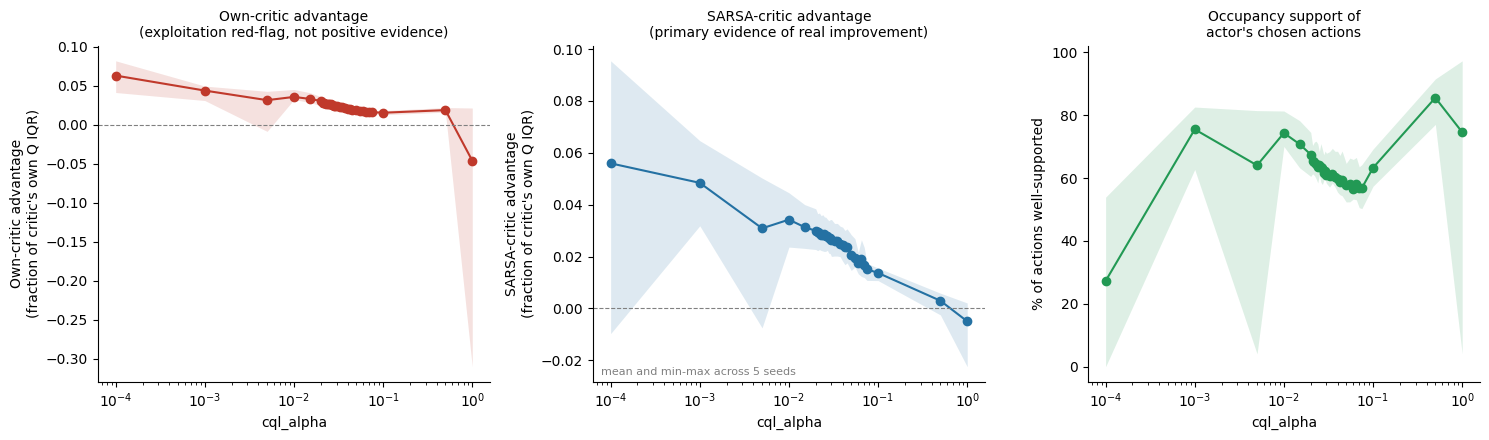

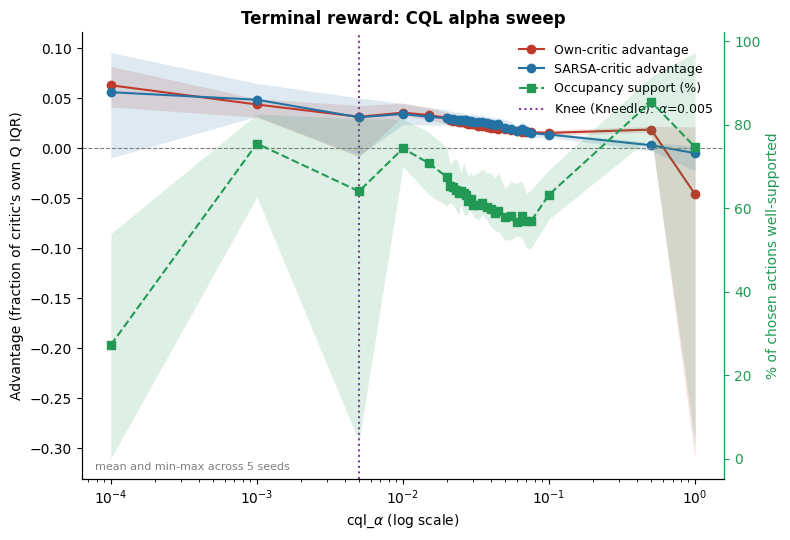

In [28]:
fig = eval_cql.plot_alpha_sweep(df_term, normalized=True, log_scale=True,
        save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_terminal.png"))
fig = eval_cql.plot_combined_alpha_sweep(df_term, normalized=True, log_scale=True,
        title="Terminal reward: CQL alpha sweep",
        save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_combined_terminal.png"))

,mean,std,n_seeds,n_seeds_positive,cv,worst_window_ratio,unstable
alpha,,,,,,,
0.0000,0.052637,0.040413,5,4,0.767773,1.155550,False
0.0001,0.055953,0.042113,5,4,0.752646,1.812131,False
0.0010,0.048421,0.012997,5,5,0.268416,1.812131,False
0.0050,0.030877,0.022387,5,4,0.725043,1.812131,False
0.0100,0.034234,0.008963,5,5,0.261821,1.568198,False
0.0150,0.031336,0.006905,5,5,0.220358,1.144358,False
0.0200,0.029916,0.006672,5,5,0.223022,1.144358,False
0.0210,0.029481,0.006342,5,5,0.215131,1.062931,False
0.0220,0.029097,0.005887,5,5,0.202323,1.038447,False


instability onset: 0.075


max_ratio,1.25,1.50,2.00,3.00,5.00
window,,,,,
3,0.0001,0.0001,0.075,0.075,0.075
4,0.0000,0.0000,0.070,0.070,0.070
5,0.0000,0.0000,0.065,0.065,0.065


Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/sarsa_stability_terminal.png


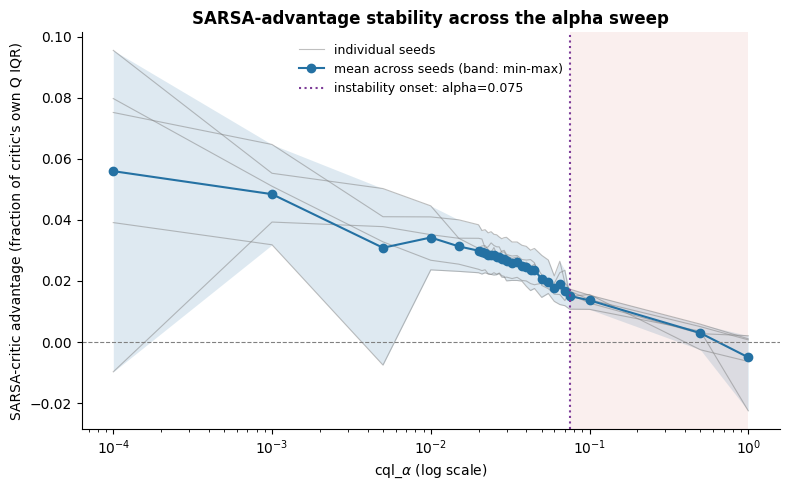

In [29]:
tab, onset = eval_cql.sarsa_stability(df_term, window=3, max_ratio=2.0)
display(tab)
print("instability onset:", onset)
display(eval_cql.stability_sensitivity(df_term))      # onset alpha across windows and thresholds

fig = eval_cql.plot_sarsa_stability(df_term, onset, normalized=True, log_scale=True,
        save_path=os.path.join(cql_model_dir, "sarsa_stability_terminal.png"))

In [30]:
final_alpha, sel_info = eval_cql.select_final_alpha(df_term, own_rule="any_seed", occupancy_margin=0.005)
display(sel_info)

alphas: 32
1. own-critic gate (any_seed): 30 pass; dropped [0.005, 1.0]
2. SARSA stability gate (window=3, max_ratio=2.0): onset=0.075; 27 survive both gates
3. occupancy: best survivor 75.48%, margin 0.50 points -> 1 tied: [0.001]
4. highest SARSA advantage among the tied: alpha=0.001 (SARSA adv 0.0484, occupancy 75.48%)


,own_adv_mean,own_adv_min,pass_own,pass_stability,sarsa_adv,occupancy,survivor,tied_occupancy,selected
alpha,,,,,,,,,
0.0000,0.072631,0.042056,True,True,0.052637,0.000000,True,False,False
0.0001,0.062888,0.041199,True,True,0.055953,0.272438,True,False,False
0.0010,0.043663,0.030899,True,True,0.048421,0.754799,True,True,True
0.0050,0.031388,-0.008623,False,True,0.030877,0.640312,False,False,False
0.0100,0.035544,0.032164,True,True,0.034234,0.743203,True,False,False
0.0150,0.033030,0.028512,True,True,0.031336,0.707725,True,False,False
0.0200,0.030350,0.024158,True,True,0.029916,0.674701,True,False,False
0.0210,0.028008,0.024143,True,True,0.029481,0.652691,True,False,False
0.0220,0.027663,0.024015,True,True,0.029097,0.651282,True,False,False


# terminal action distributions

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_fluid_terminal.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_at_clinician_zero_terminal.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_vaso_terminal.png
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/vaso_at_clinician_zero_terminal.png


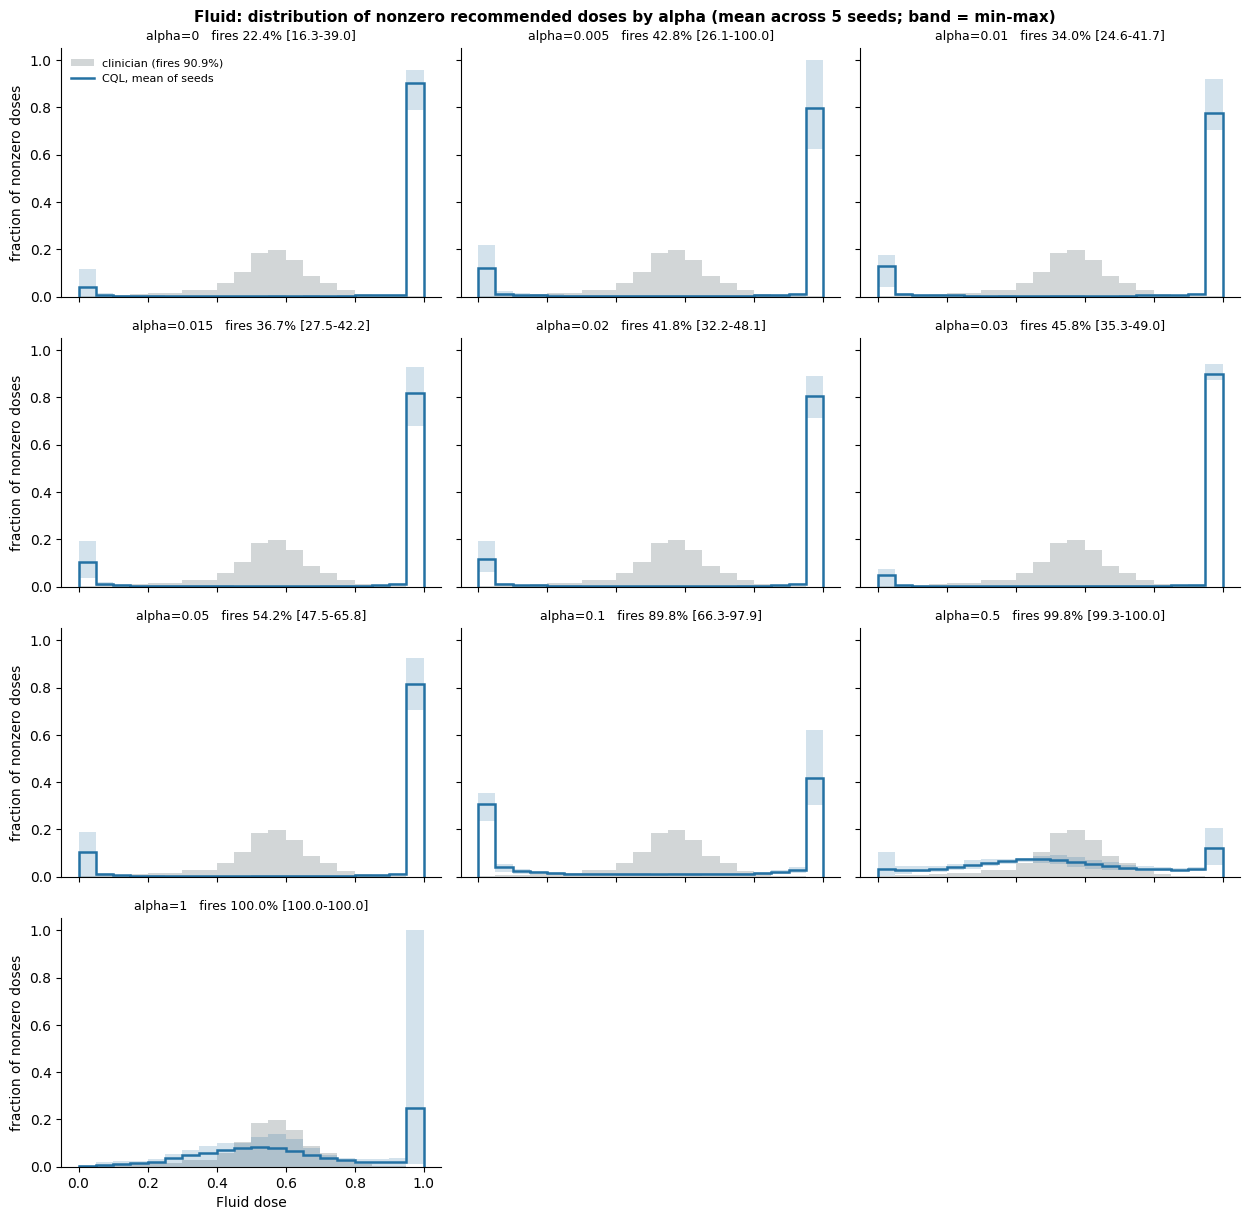

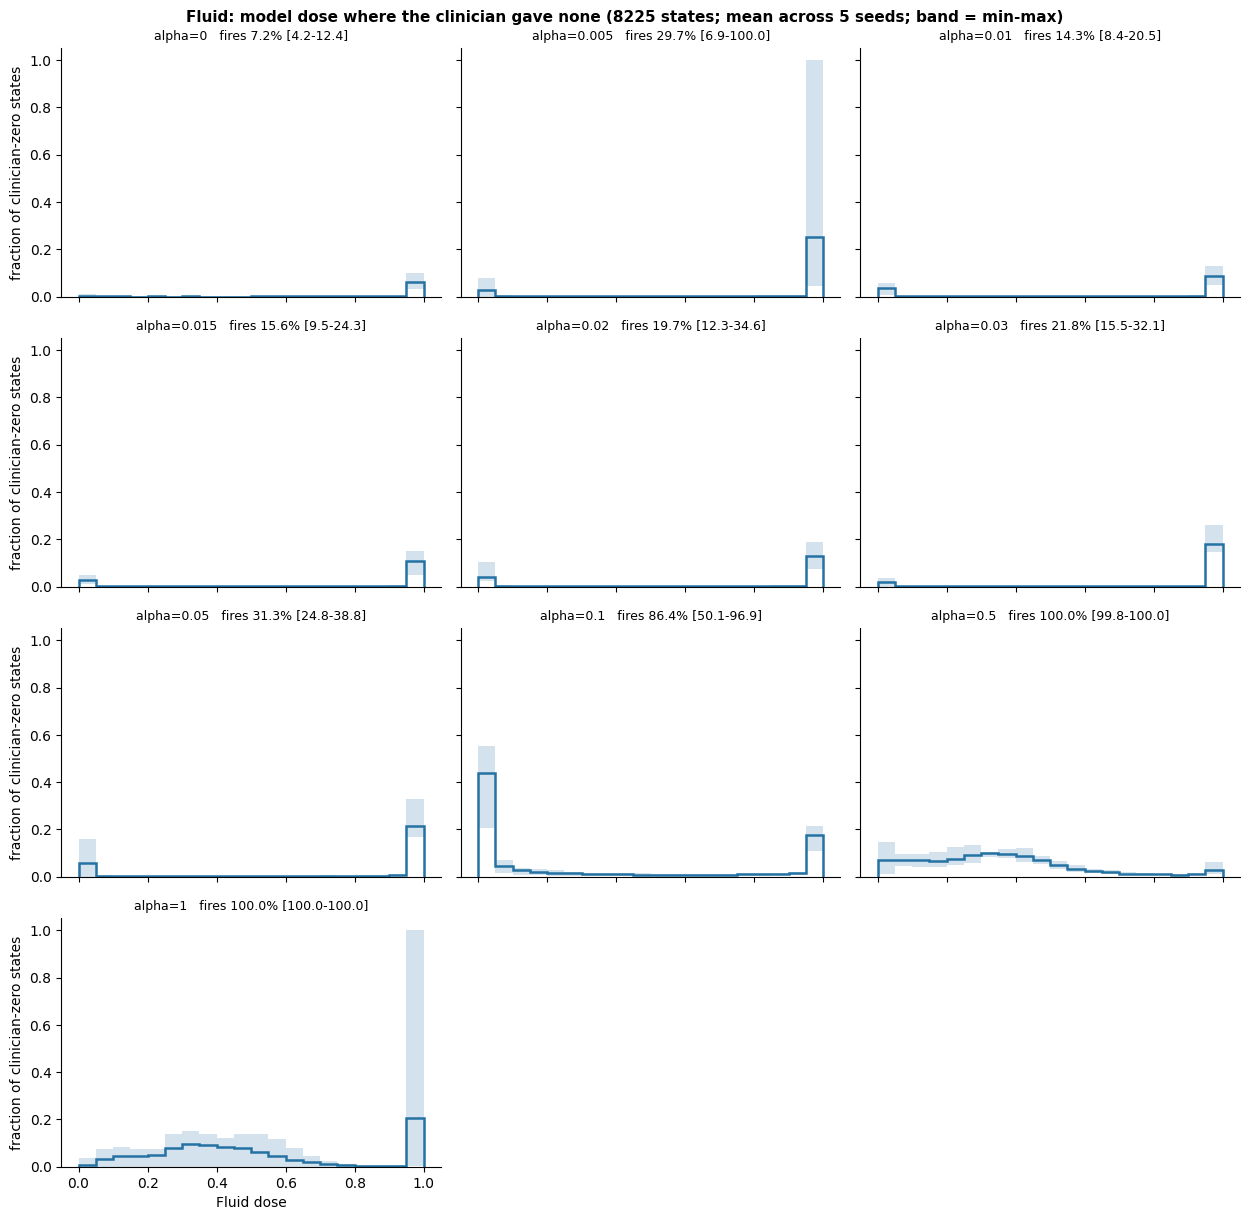

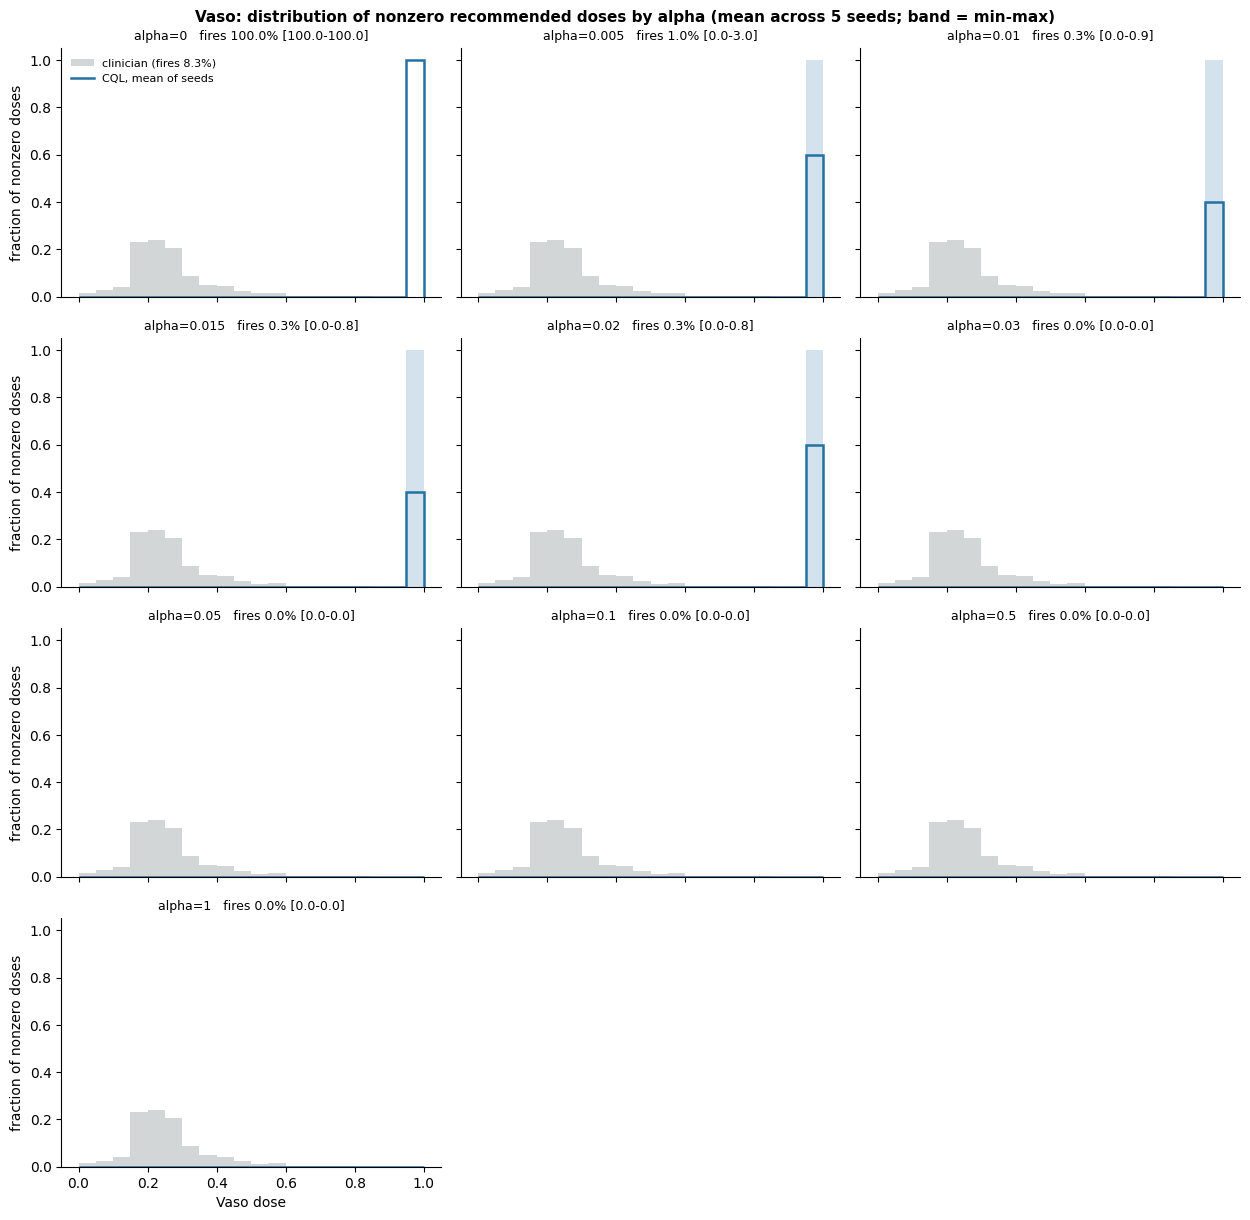

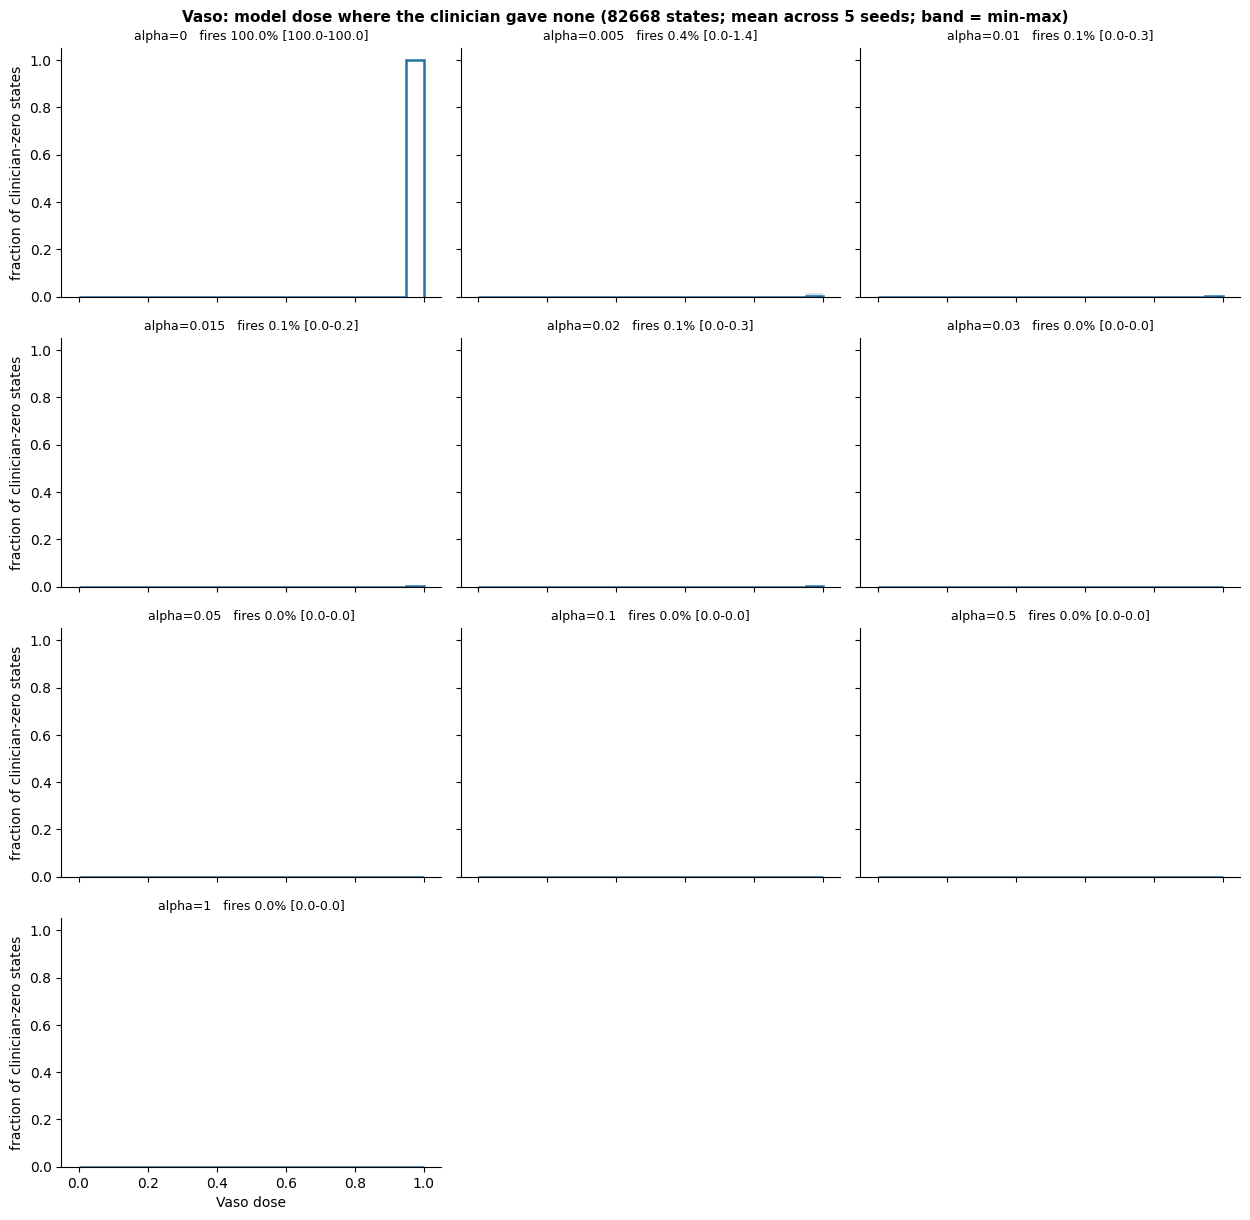

In [33]:
actions_term, clin_val = dose_hist.collect_actions(cql_term_models, store, split="val")   # once; reused by all plots

show = [0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.1, 0.5, 1.0]
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_histograms(actions_term, clin_val, dim=dim, dim_name=name, alphas_to_show=show,
        save_path=os.path.join(cql_model_dir, f"dose_histogram_{name.lower()}_terminal.png"))
    dose_hist.plot_dose_histograms_at_clinician_zero(actions_term, clin_val, dim=dim, dim_name=name, alphas_to_show=show,
        save_path=os.path.join(cql_model_dir, f"{name.lower()}_at_clinician_zero_terminal.png"))

Fluid {'fire_rate': 0.9087651965569261, 'w1': 0.0, 'low_share': 0.00346650066522636, 'high_share': 0.0030026731114284667, 'median_nz': 0.5589511394500732}


fire_rate                            w1                     low_share  \
           mean       min       max      mean       min       max      mean   
alpha                                                                         
0.015  0.366639  0.275435  0.422498  0.383514  0.357586  0.413732  0.105415   
0.020  0.417557  0.322356  0.480733  0.379016  0.363593  0.396840  0.115421   
0.025  0.447846  0.369409  0.512435  0.385803  0.363650  0.400741  0.089604   
0.030  0.457818  0.352982  0.489740  0.404958  0.391582  0.438899  0.050005   
0.035  0.506143  0.476628  0.557680  0.384367  0.352814  0.409415  0.118262   
0.050  0.542253  0.474676  0.657612  0.385533  0.362149  0.434741  0.102345   
0.100  0.898148  0.662758  0.979157  0.334781  0.314433  0.354443  0.309206   

                          high_share                     median_nz            \
            min       max       mean       min       max      mean       min   
alpha                                                                          
0.015  0.036214  0.193834   0.826885  0.694634  0.934844  0.999999  0.999998   
0.020  0.062833  0.192529   0.816787  0.725467  0.895270  1.000000  0.999999   
0.025  0.056637  0.158971   0.850657  0.748274  0.905252  0.999999  0.999993   
0.030  0.000000  0.074494   0.905777  0.879187  0.952706  1.000000  1.000000   
0.035  0.040122  0.261425   0.812942  0.602665  0.926435  0.999626  0.998135   
0.050  0.000000  0.188429   0.825056  0.718259  0.941123  0.999993  0.999965   
0.100  0.235519  0.355375   0.443540  0.330913  0.638404  0.630272  0.292898   

                 
            max  
alpha            
0.015  1.000000  
0.020  1.000000  
0.025  1.000000  
0.030  1.000000  
0.035  1.000000  
0.050  1.000000  
0.100  0.999799

Vaso {'fire_rate': 0.08301535185020854, 'w1': 0.0, 'low_share': 0.01469802244788883, 'high_share': 0.0, 'median_nz': 0.23191073536872864}


fire_rate                       w1                     low_share       \
           mean  min       max      mean       min       max      mean  min   
alpha                                                                         
0.015  0.002591  0.0  0.008042  0.743201  0.743201  0.743202       0.0  0.0   
0.020  0.002711  0.0  0.008109  0.743202  0.743202  0.743202       0.0  0.0   
0.025  0.003627  0.0  0.015807  0.743202  0.743202  0.743202       0.0  0.0   
0.030  0.000000  0.0  0.000000       NaN       NaN       NaN       NaN  NaN   
0.035  0.000000  0.0  0.000000       NaN       NaN       NaN       NaN  NaN   
0.050  0.000000  0.0  0.000000       NaN       NaN       NaN       NaN  NaN   
0.100  0.000000  0.0  0.000000       NaN       NaN       NaN       NaN  NaN   

           high_share           median_nz                 
       max       mean  min  max      mean       min  max  
alpha                                                     
0.015  0.0        1.0  1.0  1.0       1.0  0.999999  1.0  
0.020  0.0        1.0  1.0  1.0       1.0  1.000000  1.0  
0.025  0.0        1.0  1.0  1.0       1.0  1.000000  1.0  
0.030  NaN        NaN  NaN  NaN       NaN       NaN  NaN  
0.035  NaN        NaN  NaN  NaN       NaN       NaN  NaN  
0.050  NaN        NaN  NaN  NaN       NaN       NaN  NaN  
0.100  NaN        NaN  NaN  NaN       NaN       NaN  NaN

seed,0,1,2,3,4
alpha,,,,,
0.020,0.062833,0.063225,0.149091,0.109425,0.192529
0.021,0.046969,0.169641,0.083444,0.064233,0.177971
0.022,0.050616,0.056811,0.202972,0.055101,0.202713
0.023,0.040325,0.050955,0.111999,0.273894,0.164325
0.024,0.042281,0.058249,0.101090,0.206601,0.217252
0.025,0.059431,0.056637,0.107100,0.065880,0.158971
0.026,0.060251,0.053985,0.107931,0.233051,0.195919
0.027,0.035079,0.047111,0.080875,0.230789,0.000000
0.028,0.044331,0.057781,0.060983,0.068690,0.000000


seed,0,1,2,3,4
alpha,,,,,
0.020,0.393968,0.396840,0.363593,0.374941,0.365737
0.021,0.404354,0.369721,0.385416,0.394984,0.367544
0.022,0.401070,0.401420,0.358142,0.399542,0.364312
0.023,0.410537,0.404264,0.373388,0.359339,0.363619
0.024,0.407921,0.400265,0.374578,0.358583,0.363418
0.025,0.395845,0.400741,0.372397,0.396382,0.363650
0.026,0.393606,0.403856,0.373642,0.356578,0.365115
0.027,0.414480,0.408346,0.387537,0.360043,0.438934
0.028,0.405646,0.401078,0.400491,0.393144,0.438445


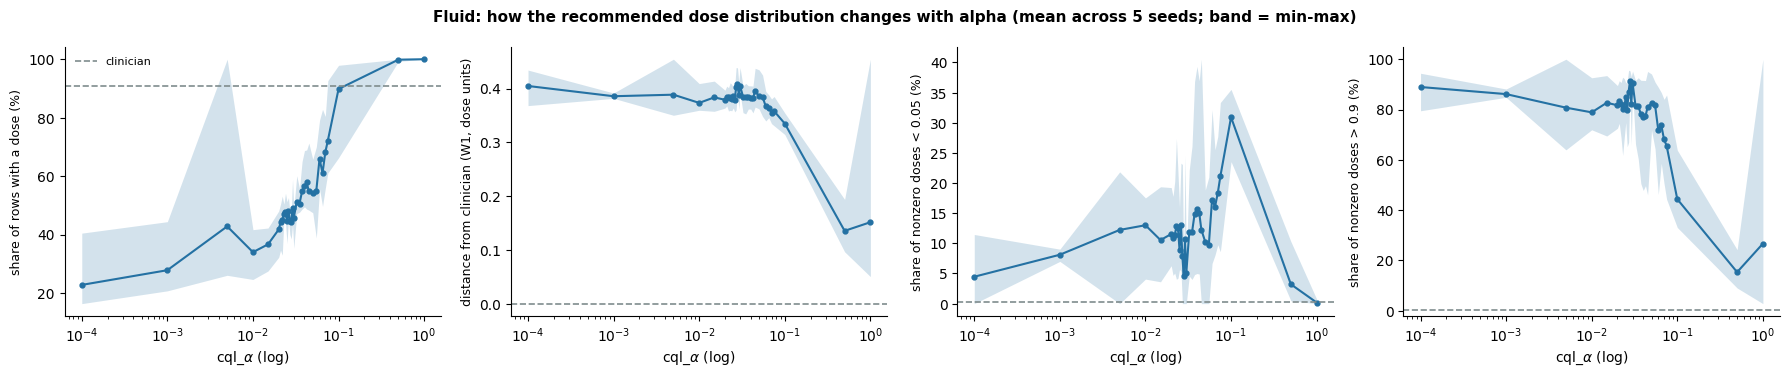

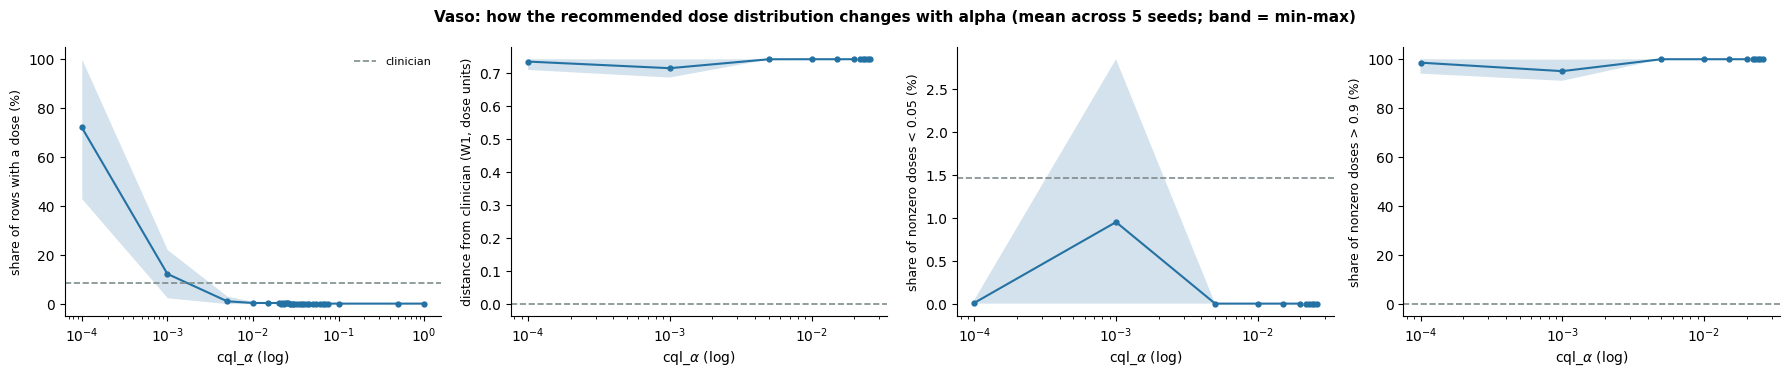

In [32]:
import importlib; importlib.reload(dose_hist)

dm = {name: dose_hist.dose_distribution_metrics(actions_term, clin_val, dim)
      for dim, name in [(0, "Fluid"), (1, "Vaso")]}

# Seed-averaged table for the candidates, plus the clinician reference
cand = [0.015, 0.02, 0.025, 0.03, 0.035, 0.05, 0.1]
for name in dm:
    print(name, dose_hist.clinician_reference(clin_val, 0 if name == "Fluid" else 1))
    display(dose_hist.summarize_metrics(dm[name]).loc[cand])

# Metrics vs alpha (clinician as dashed line)
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    dose_hist.plot_dose_metrics(dm[name], clin_val, dim, name, save_path=None)

# Dense grid between 0.02 and 0.03: where does the low-dose tail disappear, and do all 5 seeds agree?
dense = dm["Fluid"][dm["Fluid"].alpha.between(0.02, 0.03)]
display(dense.pivot(index="alpha", columns="seed", values="low_share"))
display(dense.pivot(index="alpha", columns="seed", values="w1"))

,bin,n,fire_rate,mean_dose,median_nz,low_share,w1
0,0,18031,0.987078,0.569815,0.572926,0.000730,0.0
1,1,18030,0.963006,0.532074,0.560700,0.001325,0.0
2,2,18030,0.928841,0.500977,0.556382,0.002866,0.0
3,3,18030,0.894676,0.477604,0.554674,0.005579,0.0
4,4,18031,0.770229,0.398417,0.542683,0.007921,0.0


w1                             low_share                       \
bin        0      1      2      3      4         0      1      2      3   
alpha                                                                     
0.025  0.413  0.382  0.361  0.348  0.334     0.009  0.098  0.171  0.271   
0.030  0.417  0.402  0.383  0.368  0.351     0.004  0.050  0.093  0.152   
0.050  0.404  0.393  0.376  0.368  0.369     0.030  0.077  0.132  0.206   
0.100  0.360  0.337  0.322  0.341  0.362     0.103  0.201  0.262  0.447   
0.500  0.164  0.161  0.117  0.141  0.172     0.003  0.028  0.034  0.054   
1.000  0.165  0.185  0.137  0.173  0.188     0.000  0.000  0.003  0.004   

             fire_rate                              
bin        4         0      1      2      3      4  
alpha                                               
0.025  0.389     0.981  0.699  0.352  0.141  0.067  
0.030  0.244     0.978  0.712  0.379  0.160  0.060  
0.050  0.380     0.936  0.786  0.542  0.289  0.159  
0.100  0.558     0.935  0.893  0.893  0.890  0.879  
0.500  0.042     1.000  0.996  0.997  1.000  1.000  
1.000  0.002     1.000  1.000  1.000  1.000  1.000

,bin,n,fire_rate,mean_dose,median_nz,low_share,w1
0,0,18031,0.231047,0.064322,0.257637,0.005281,0.0
1,1,18030,0.097449,0.023246,0.221994,0.050085,0.0
2,2,18030,0.048475,0.010957,0.221994,0.000000,0.0
3,3,18030,0.028674,0.006406,0.221994,0.000000,0.0
4,4,18031,0.009428,0.001682,0.155214,0.000000,0.0


w1                 low_share                 fire_rate            \
bin        0   1   2   3   4         0   1   2   3   4         0    1    2   
alpha                                                                        
0.025  0.722 NaN NaN NaN NaN       0.0 NaN NaN NaN NaN     0.018  0.0  0.0   
0.030    NaN NaN NaN NaN NaN       NaN NaN NaN NaN NaN     0.000  0.0  0.0   
0.050    NaN NaN NaN NaN NaN       NaN NaN NaN NaN NaN     0.000  0.0  0.0   
0.100    NaN NaN NaN NaN NaN       NaN NaN NaN NaN NaN     0.000  0.0  0.0   
0.500    NaN NaN NaN NaN NaN       NaN NaN NaN NaN NaN     0.000  0.0  0.0   
1.000    NaN NaN NaN NaN NaN       NaN NaN NaN NaN NaN     0.000  0.0  0.0   

                 
bin      3    4  
alpha            
0.025  0.0  0.0  
0.030  0.0  0.0  
0.050  0.0  0.0  
0.100  0.0  0.0  
0.500  0.0  0.0  
1.000  0.0  0.0

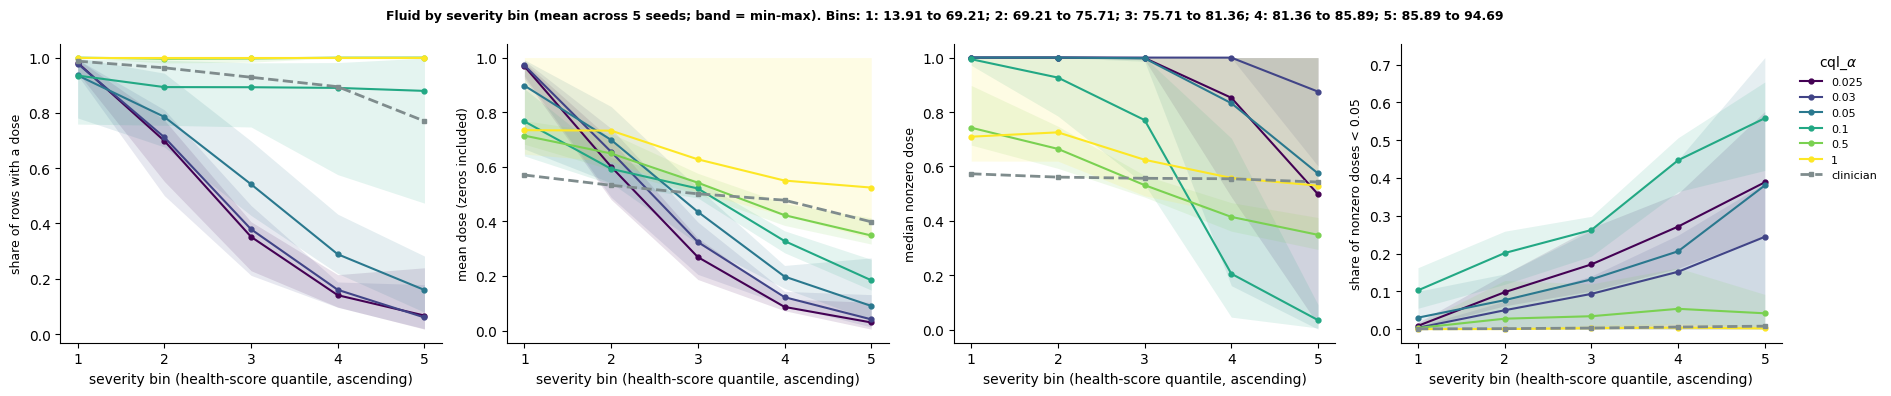

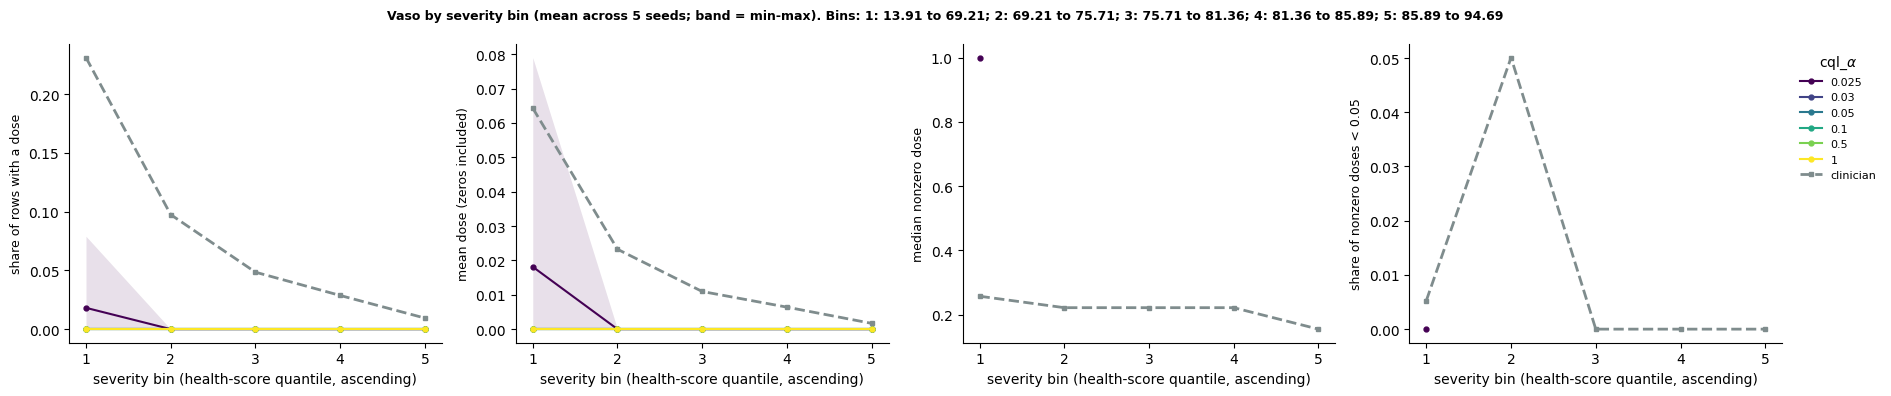

In [34]:
importlib.reload(dose_hist)

term_val = dose_hist.collect_severity(cql_term_models, store, split="val")

show = [0.025, 0.03, 0.05, 0.1, 0.5, 1.0]
sev = {}
for dim, name in [(0, "Fluid"), (1, "Vaso")]:
    sev[name] = dose_hist.dose_by_severity(actions_term, clin_val, term_val, dim, n_bins=5)
    df_s, clin_s, labels = sev[name]
    dose_hist.plot_dose_by_severity(df_s, clin_s, labels, name, show, save_path=None)

# Tables: clinician per bin, and seed-mean W1 / low share per alpha x bin for fluid
df_f, clin_f, labels = sev["Fluid"]
display(clin_f)
display(df_f[df_f.alpha.isin(show)].groupby(["alpha", "bin"])[["w1", "low_share", "fire_rate"]].mean().unstack("bin").round(3))

df_v, clin_v, labels = sev["Vaso"]
display(clin_v)
display(df_v[df_v.alpha.isin(show)].groupby(["alpha", "bin"])[["w1", "low_share", "fire_rate"]].mean().unstack("bin").round(3))

Terminal-reward models: why no alpha was selected

We repeated the full alpha sweep (32 values, 5 seeds each) for CQL models trained on the terminal-outcome reward, using the same Dynamic-DeepHit states as the health-score (HS) models. We evaluated them with the same independent SARSA critics and the same dose-distribution diagnostics. No alpha gave a policy that was both well supported by the clinician data and judged beneficial by independent critics, so the frozen selection rule returned no alpha for this reward.

Fluid. Across α=0.015–0.05, fired fluid doses were overwhelmingly at the ceiling: 83–91% were above 0.9 and the median fired dose was 1.0. The distance (Wasserstein-1) from the clinicians’ nonzero dose distribution was about 0.38–0.41. The fire rate (0.37–0.54) fell well short of the clinicians’ (about 0.9) and fell steeply with improving health, so the policy withheld fluid from healthier patients far more than clinicians do. At low alphas, support (the fraction of states where the chosen dose bin has ≥10 training examples) was poor (about 0.6 at α=0.03–0.05, and 0 at α=0), because the ceiling dose is rarely used clinically. As alpha rose, fluid dosing moved towards the clinicians’: by α=0.1 the fire rate was 0.90 and the median fired dose 0.63, and by α=0.5 the W1 distance fell to 0.12–0.19. But this convergence came with the advantage shrinking to nothing: the SARSA advantage was 0.014 at α=0.1, 0.003 at α=0.5, and −0.005 at α=1.0, where the own-critic advantage was also negative in at least one seed. Higher alpha therefore gives approximately clinician behaviour, not an improvement on it.

Vasopressors. The terminal models essentially never gave vasopressors. The fire rate was under 2% in any seed up to α=0.025 and exactly zero for every seed from α=0.03 up to α=1.0; the few doses given were all at the maximum. Clinicians gave vasopressors to 23% of the sickest fifth of patients. We interpret this as confounding by indication: vasopressors go to the sickest patients, who have the worst terminal outcomes, so a critic trained on outcomes alone learns that vasopressors predict poor outcomes and a policy maximising it avoids them. We did not test this directly. Raising alpha did not fix it, since CQL regularises towards the data but cannot correct a biased value estimate.

Health-score models: scope of the claim

The HS models do produce vasopressor recommendations, which shows the architecture is capable of learning a vasopressor gate. But vasopressor dosing was inconsistent across seeds [quote the per-seed fire rates from your table: mean 0.040, minimum 0.031, clinician 0.083], so we do not claim a vasopressor policy. We treat the HS models as effectively fluid-only policies, and our claims concern fluid dosing.

Fluid comparison

On fluid, the HS model at the selected alpha (0.029) is clearly better behaved than any terminal model:

	HS, α=0.029	Terminal, α=0.03	Terminal, α=0.1	Terminal, α=0.5
Fluid fire rate (clinician ≈0.91)	0.87	0.46	0.90	≈1.0
W1 vs clinician doses	0.147	0.405	0.335	≈0.12–0.19
Fired doses >0.9	[fill from HS table]	0.91	0.44	[fill]
Support (mean)	0.988	≈0.61	0.63	0.86
Own-critic advantage positive	5 of 5 seeds	[fill]	[fill]	[fill]
SARSA advantage (normalised)	0.217	0.027	0.014	0.003

The HS model is the only one that has a fire rate near the clinicians’, doses close to the clinicians’ shape, high support, and a clearly positive advantage at the same time. The terminal models trade those against each other: close to the clinicians only when the advantage vanishes, and apparently beneficial only when the doses are unsupported.

Caveat on the table. The normalised advantages are each measured against their own reward’s critics and scaled by that critic’s own IQR, so they are not comparable across rewards. The fire rate, W1 and support rows are reward-independent and carry the comparison. A like-for-like benefit comparison would need one reward’s critic to judge both model families, which we have not done.

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_two_population_by_vaso.png


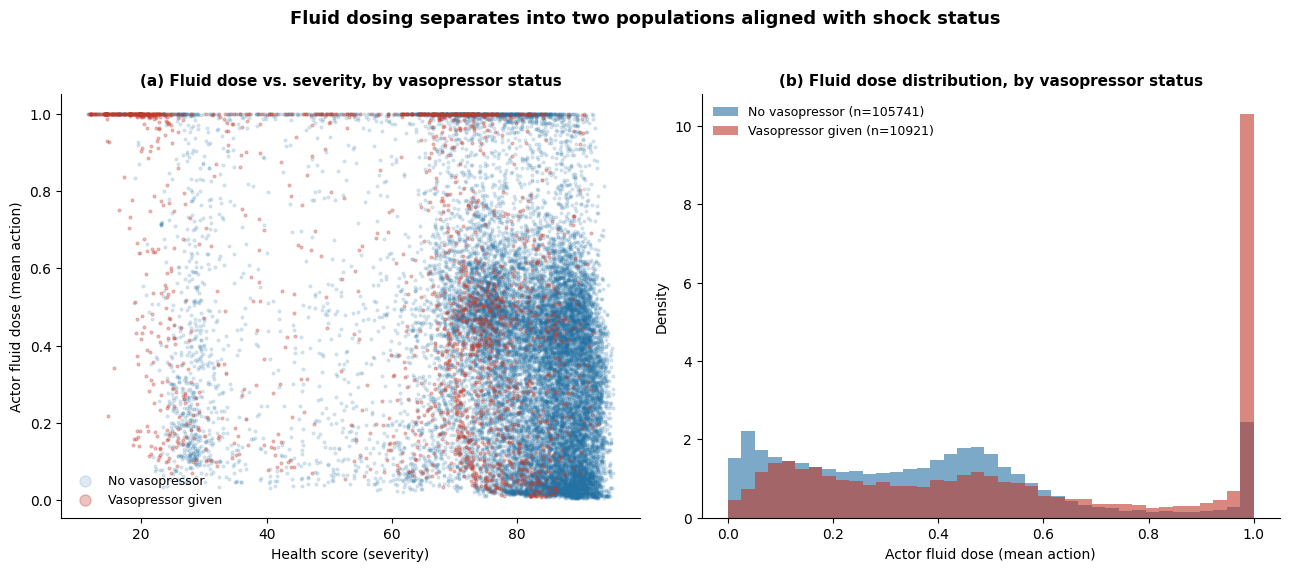

In [17]:
clinician_actions_test = processors['test'].rl_dataset["actions"]
fig = fluid_pop.plot_fluid_spike_by_severity_and_vaso(
    f_raw_mean, test_health_score, clinician_actions_test,
    save_path=os.path.join(cql_model_dir, "fluid_two_population_by_vaso.png"),
)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_dose_severity_heatmaps_normalized.png

Fraction of ALL states with dose>0.9: 0.1002
Fraction of states with dose>0.9 that are ALSO (health_score>70 AND no vaso): 0.4329
  (i.e. this fraction of the high-dose spike is NOT explained by sickness+vaso)
For comparison, (health_score>70 AND no vaso) as a fraction of ALL states: 0.7837
  (if the two numbers above are similar, the spike is NOT concentrated away from this group -- i.e. sickness/vaso does NOT explain the spike)


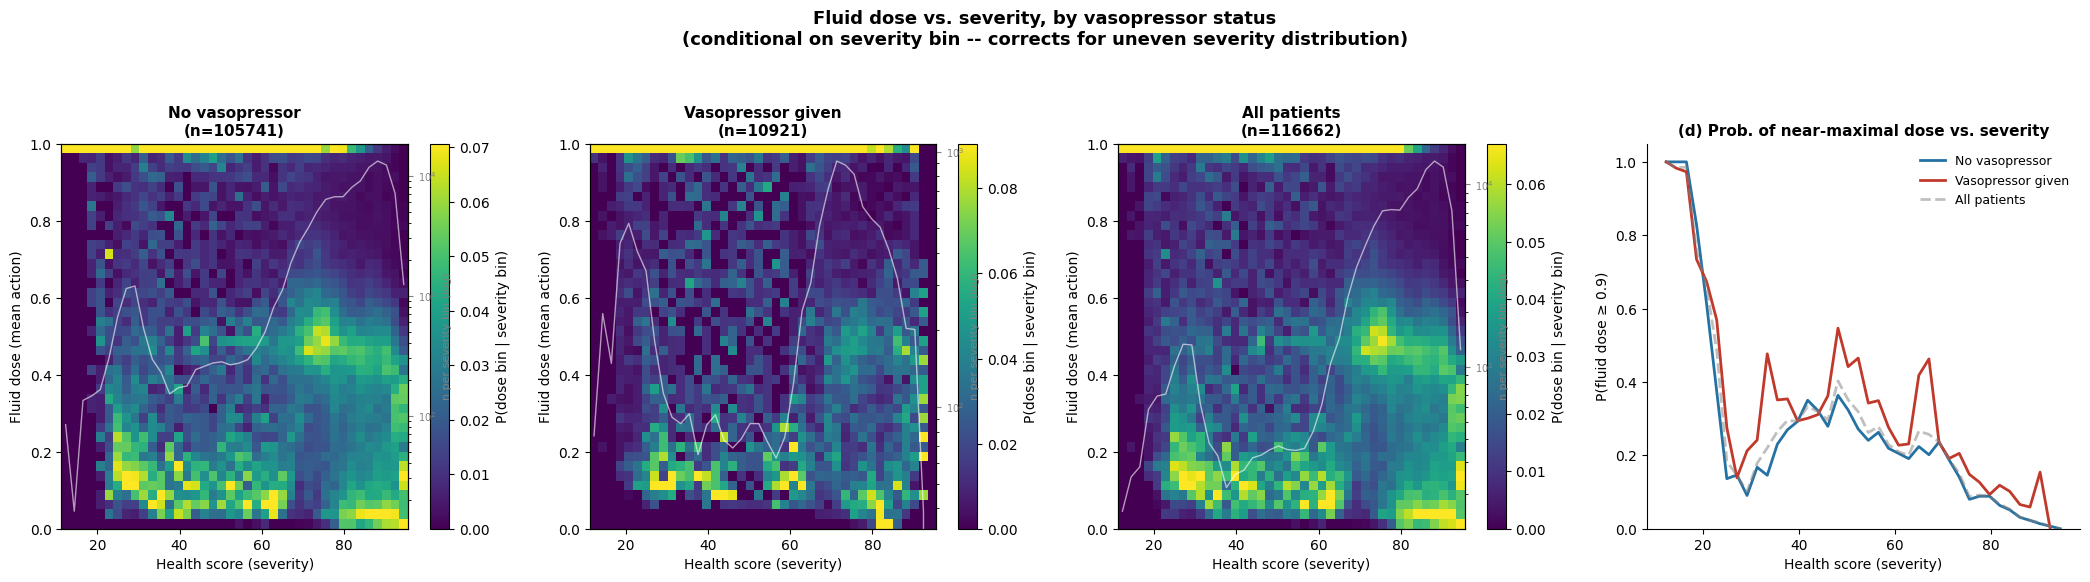

In [19]:
clinician_actions_test = processors['test'].rl_dataset["actions"]
fig = heatmap_diag.plot_fluid_dose_severity_heatmaps(
    f_raw_mean, test_health_score, clinician_actions_test,
    normalize="severity_bin",
    save_path=os.path.join(cql_model_dir, "fluid_dose_severity_heatmaps_normalized.png"),
)

## terminal models

=== alpha=0.0 ===


    own-critic Q IQR (real clinician actions): 3.4619
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2745, normalized=0.0793
  SARSA-critic advantage: raw mean=0.2798, normalized mean=0.0809 (normalized per-seed=[0.0829 0.0929 0.0698 0.0855 0.0736])
  occupancy support of chosen actions: 83.1%
  done in 6.1s

=== alpha=0.0001 ===
    own-critic Q IQR (real clinician actions): 3.4603
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2701, normalized=0.0781
  SARSA-criti

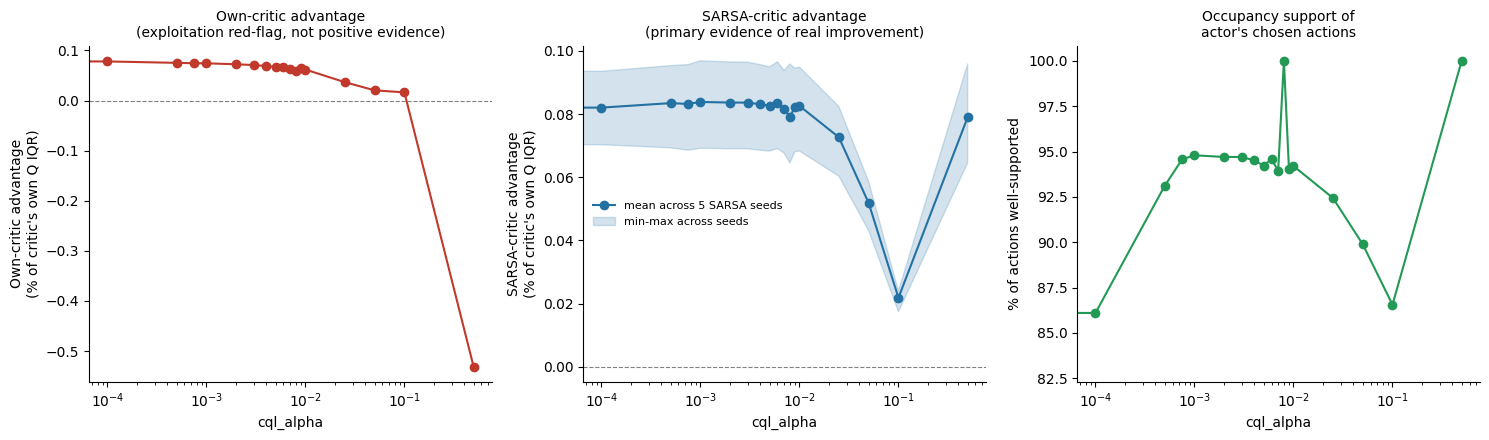

In [38]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_terminal_n_severity_bins_100.png")    


# --- Health-score reward: CQL alpha sweep vs. all 5 health-score SARSA seeds ---
results_terminal, fig_terminal = eval_cql.run_alpha_sweep_analysis(
    cql_terminal_by_alpha,
    processors['val'],
    basic_q_terminal_models,   # the 5 health-score SARSA seeds, as independent judges
    val_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 100,
    save_path=save_path,
)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_terminal_n_severity_bins_100.png


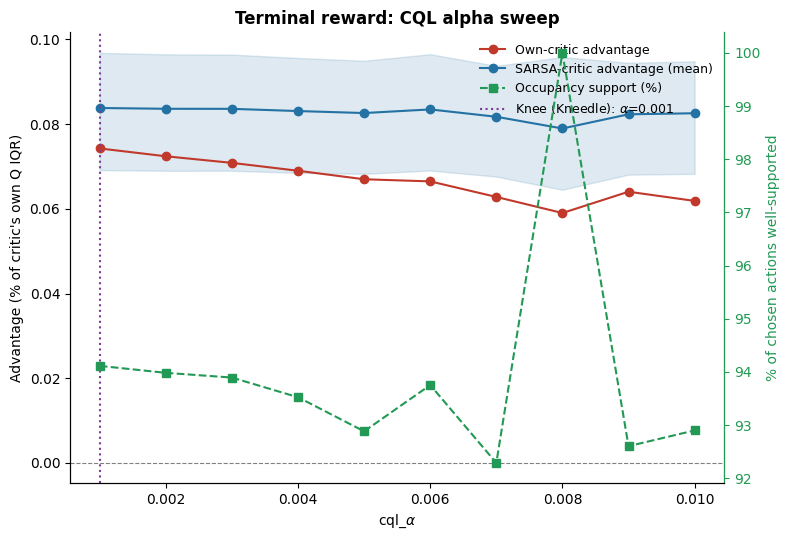

In [17]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_combined_terminal_n_severity_bins_100.png")  

fig = eval_cql.plot_combined_alpha_sweep(
    results_terminal,
    normalized=True,
    title="Terminal reward: CQL alpha sweep",
    save_path=save_path,
)

alpha=0.001: fluid[rate=10.9%, mean=0.1081, nonzero_mean=0.9903]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.002: fluid[rate=12.3%, mean=0.1127, nonzero_mean=0.9183]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.003: fluid[rate=11.4%, mean=0.1139, nonzero_mean=0.9995]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.004: fluid[rate=12.0%, mean=0.1199, nonzero_mean=0.9956]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.005: fluid[rate=13.5%, mean=0.1347, nonzero_mean=0.9957]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.006: fluid[rate=11.8%, mean=0.1178, nonzero_mean=0.9978]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.007: fluid[rate=16.5%, mean=0.1510, nonzero_mean=0.9155]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.008: fluid[rate=0.0%, mean=0.0000, nonzero_mean=nan]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.009: fluid[rate=14.1%, mean=0.1409, nonzero_mean=0.9970]  vaso[rate=0.0%, mean=0.0000, nonze

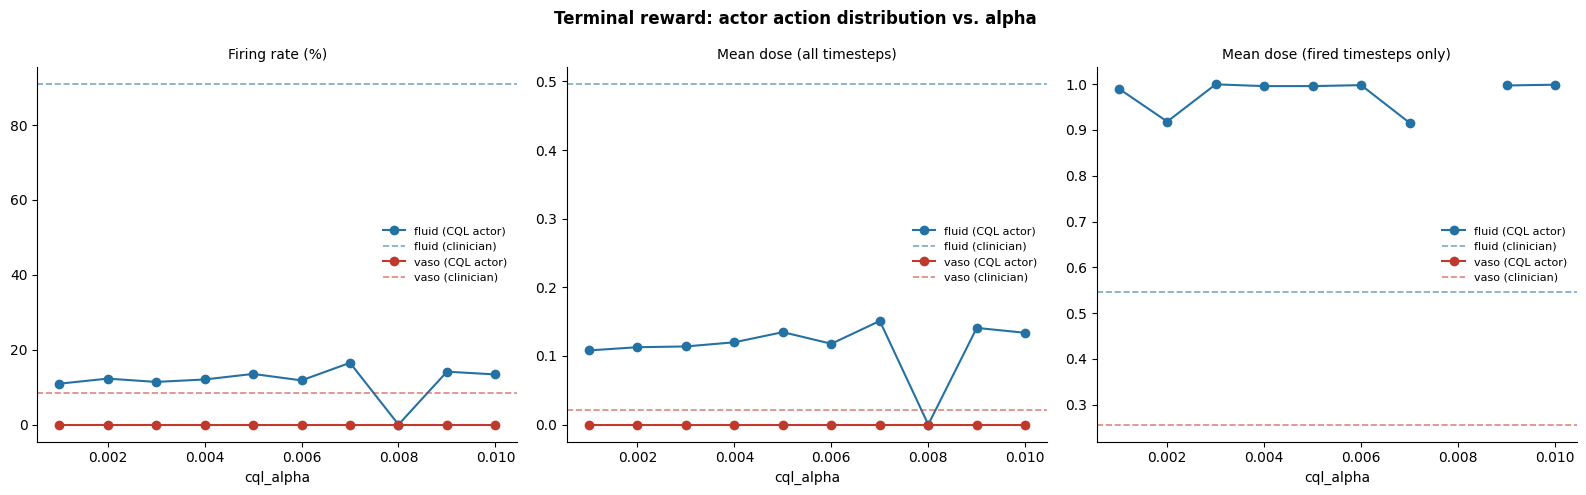

In [31]:
clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])

results_actions_terminal, fig_actions_terminal = action_dist.run_action_distribution_sweep(
    cql_terminal_by_alpha,
    processors['val'],
    clinician_baseline=clinician_baseline_val,
    title="Terminal reward: actor action distribution vs. alpha",
    save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_actions_terminal.png"),
)

alpha=0.001: fluid[rate=30.3%, mean=0.2437, nonzero_mean=0.8053]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.002: fluid[rate=56.3%, mean=0.3414, nonzero_mean=0.6069]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.003: fluid[rate=77.5%, mean=0.4594, nonzero_mean=0.5930]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.004: fluid[rate=87.2%, mean=0.4952, nonzero_mean=0.5676]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.005: fluid[rate=94.8%, mean=0.4810, nonzero_mean=0.5077]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.006: fluid[rate=97.2%, mean=0.4264, nonzero_mean=0.4387]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.007: fluid[rate=97.1%, mean=0.4561, nonzero_mean=0.4698]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.008: fluid[rate=99.1%, mean=0.4676, nonzero_mean=0.4717]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.009: fluid[rate=99.8%, mean=0.4724, nonzero_mean=0.4736]  vaso[rate=0.0%, mean=0.0000, n

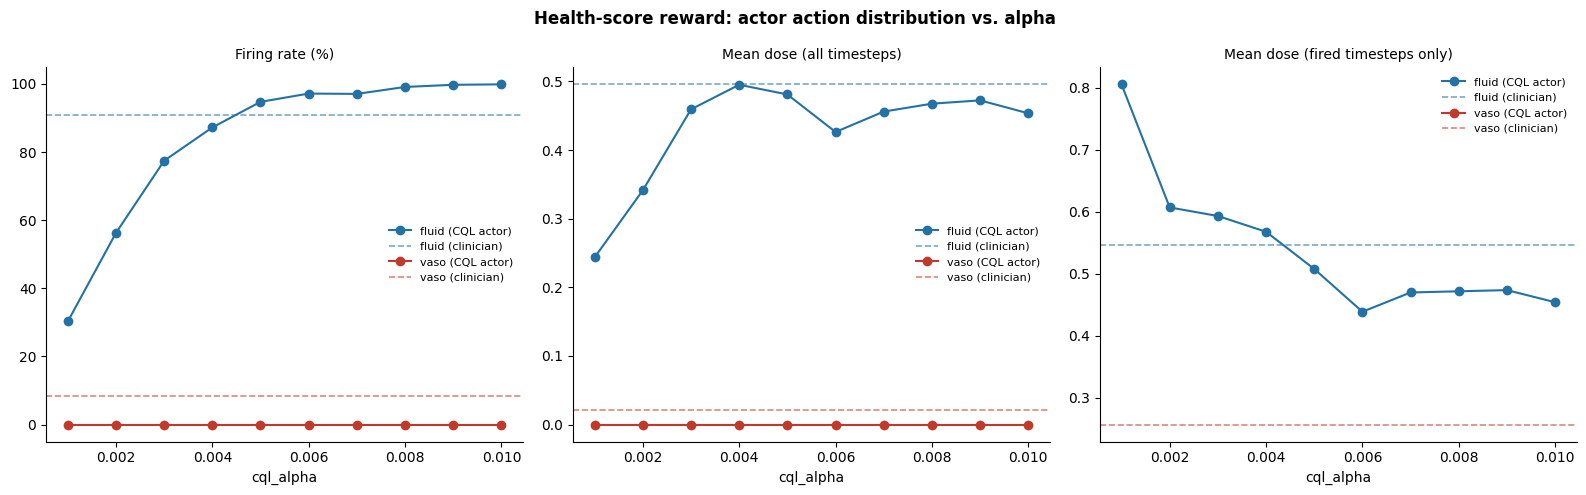

In [32]:
results_actions_health_score, fig_actions_health_score = action_dist.run_action_distribution_sweep(
    cql_health_score_by_alpha,
    processors['val'],
    clinician_baseline=clinician_baseline_val,
    title="Health-score reward: actor action distribution vs. alpha",
    save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_actions_health_score.png"),
)

# final 5 seed models with fixed cql alpha

In [20]:
cql_model_dir

'/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset'

In [21]:
cql_terminal_fixed_alpha_model_dir = os.path.join(cql_model_dir, "terminal_only", "fixed_alpha")
cql_terminal_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_terminal_fixed_alpha_model_dir)

cql_terminal_fixed_alpha_models = []
for model_dir in cql_terminal_fixed_alpha_model_dirs:
    # load terminal sarsa model
    terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_terminal_fixed_alpha_models.append((terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-220822_0ce993d0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-223125_f7922617
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-215444_c0ab74de
Found model directory: /home/ja

In [23]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-110857_6a599bed
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-095956_924ca060
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-101849_70f2dd3

seed 1/5: fluid[rate=93.2%, mean=0.4356, nonzero_mean=0.4677]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=93.3%, mean=0.4161, nonzero_mean=0.4458]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=92.5%, mean=0.3793, nonzero_mean=0.4102]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=95.4%, mean=0.3856, nonzero_mean=0.4043]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 5/5: fluid[rate=98.7%, mean=0.4178, nonzero_mean=0.4234]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_health_score.png


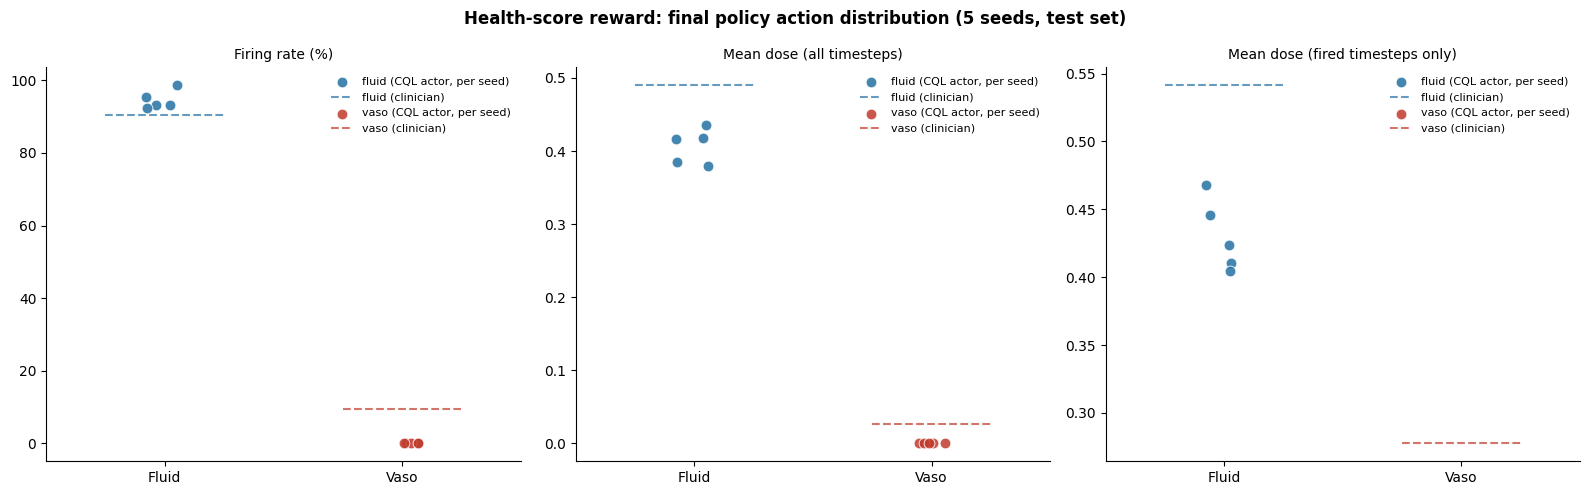

In [24]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])

stats_health_score, fig_health_score = action_dist.run_action_distribution_stage3(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Health-score reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_health_score.png"),
)

In [26]:
all_f_std, all_v_std = std_check.check_std_floor_across_seeds(
    cql_health_score_fixed_alpha_models,
    processors['val'],
)

Floor std (exp(log_std_min=-2.0)) = 0.1353
Ceiling std (exp(log_std_max=1.0)) = 2.7183

seed 1: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2166, min=0.1353, max=0.2815, %_at_floor=3.0%]
seed 2: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2014, min=0.1353, max=0.2508, %_at_floor=1.1%]
seed 3: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2637, min=0.1353, max=0.3252, %_at_floor=0.1%]
seed 4: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.1692, min=0.1353, max=0.2318, %_at_floor=23.9%]
seed 5: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2904, min=0.1353, max=0.4013, %_at_floor=0.1%]

Across all 5 seeds combined: f_std mean=0.1353 (100.0% at floor), v_std mean=0.2283 (5.6% at floor)


seed 1/5: fluid[rate=19.9%, mean=0.1784, nonzero_mean=0.8979]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=15.6%, mean=0.1441, nonzero_mean=0.9243]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=13.8%, mean=0.1362, nonzero_mean=0.9902]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=15.0%, mean=0.1409, nonzero_mean=0.9381]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 5/5: fluid[rate=12.0%, mean=0.1153, nonzero_mean=0.9619]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_terminal.png


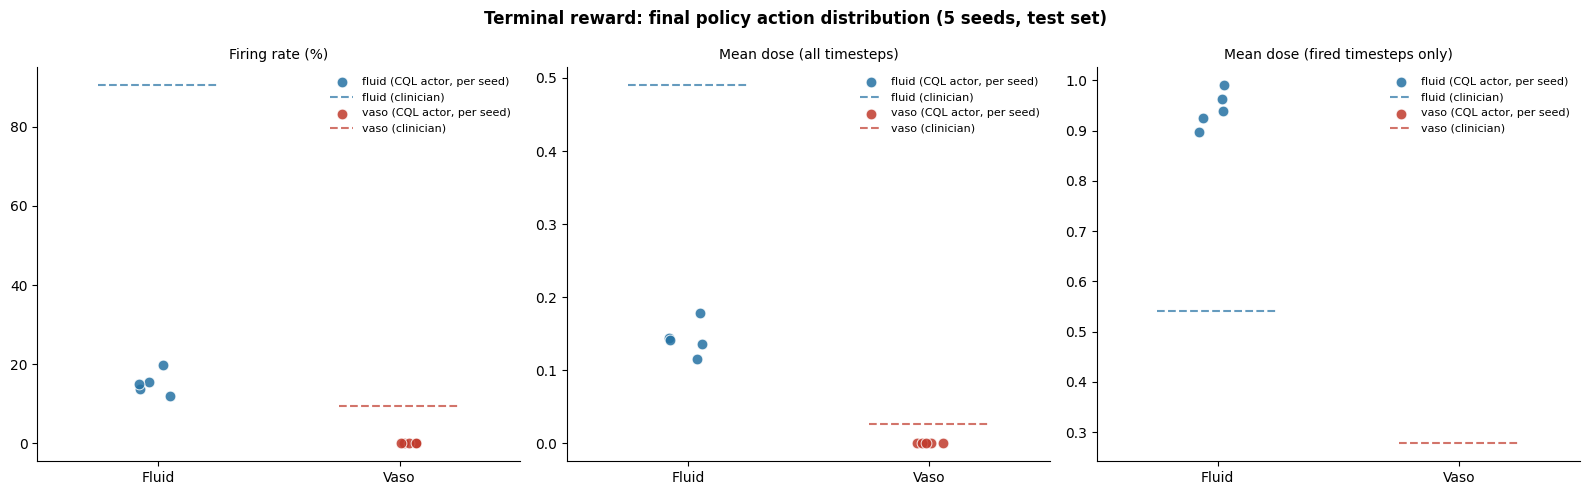

In [39]:
stats_terminal, fig_terminal = action_dist.run_action_distribution_stage3(
    cql_terminal_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Terminal reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_terminal.png"),
)

# reward by vaso 

Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): 0.0440
Total vaso-given timesteps contributing to estimate: 10921
  bin center hs=34.0: vaso mean=0.000447 (n=3660), no_vaso mean=0.095069 (n=8007)
  bin center hs=68.1: vaso mean=0.013176 (n=2498), no_vaso mean=0.016489 (n=9168)
  bin center hs=73.9: vaso mean=0.078589 (n=1616), no_vaso mean=0.082335 (n=10050)
  bin center hs=77.5: vaso mean=-0.013044 (n=1041), no_vaso mean=0.044067 (n=10625)
  bin center hs=80.8: vaso mean=0.041779 (n=793), no_vaso mean=0.066261 (n=10873)
  bin center hs=83.7: vaso mean=0.063762 (n=539), no_vaso mean=0.047470 (n=11127)
  bin center hs=86.1: vaso mean=-0.134604 (n=326), no_vaso mean=0.029251 (n=11340)
  bin center hs=88.0: vaso mean=-0.038649 (n=172), no_vaso mean=-0.012884 (n=11494)
  bin center hs=89.8: vaso mean=-0.004516 (n=203), no_vaso mean=-0.023176 (n=11463)
  bin center hs=92.1: vaso mean=0.015111 (n=73), no_vaso mean=-0.037300 (n=11594)
Saved to /home/jake/Documents/AI

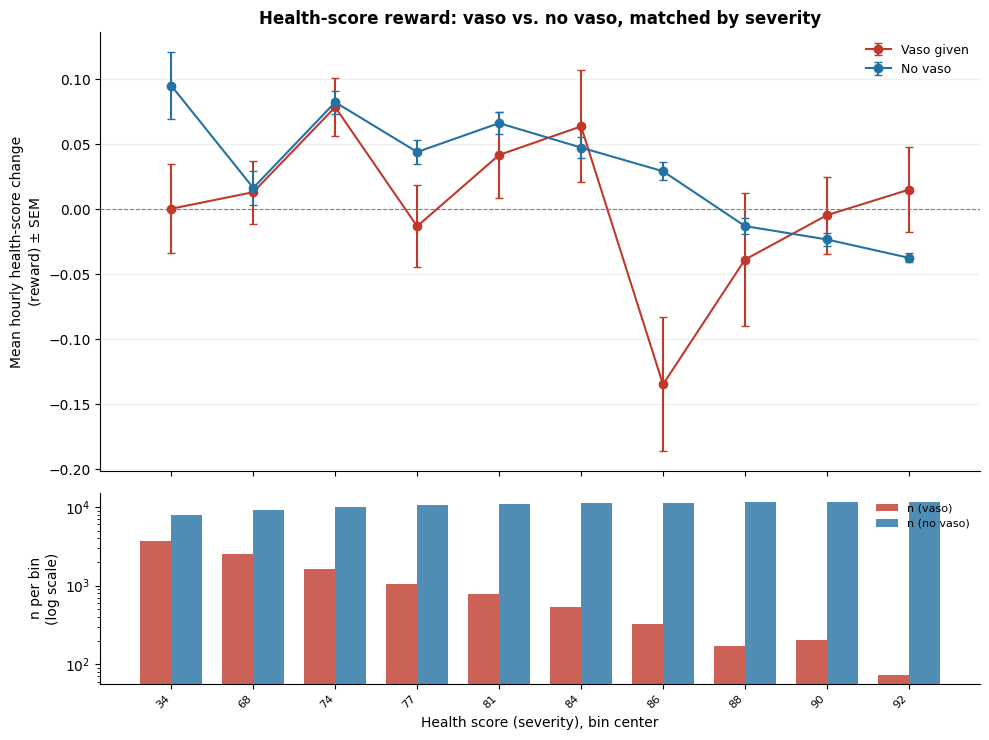

In [65]:
test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

rewards = processors['test'].rl_dataset["rewards"]
actions = processors['test'].rl_dataset["actions"]

health_score = processors['test'].dynamic_deephit_predictions['health_score'] 

results = vaso_match.compare_reward_by_vaso(
    rewards, actions, test_health_score, n_severity_bins=10
)

effect, total_n_vaso = vaso_match.matched_effect_estimate(results)
print(f"Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): {effect:.4f}")
print(f"Total vaso-given timesteps contributing to estimate: {total_n_vaso}")

for b in range(len(results["bin_center_health_score"])):
    print(f"  bin center hs={results['bin_center_health_score'][b]:.1f}: "
      f"vaso mean={results['mean_reward_vaso'][b]:.6f} (n={results['n_vaso'][b]}), "
      f"no_vaso mean={results['mean_reward_no_vaso'][b]:.6f} (n={results['n_no_vaso'][b]})")

fig = vaso_match.plot_reward_by_vaso(
    results,
    title="Health-score reward: vaso vs. no vaso, matched by severity",
    save_path=os.path.join(cql_model_dir, "reward_by_vaso_matched.png"),
)

In [1]:
val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

rewards = processors['val'].rl_dataset["rewards"]
actions = processors['val'].rl_dataset["actions"]

health_score = processors['val'].dynamic_deephit_predictions['health_score'] 

results = vaso_match.compare_reward_by_vaso(
    rewards, actions, val_health_score, n_severity_bins=10
)

effect, total_n_vaso = vaso_match.matched_effect_estimate(results)
print(f"Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): {effect:.4f}")
print(f"Total vaso-given timesteps contributing to estimate: {total_n_vaso}")

for b in range(len(results["bin_center_health_score"])):
    print(f"  bin center hs={results['bin_center_health_score'][b]:.1f}: "
      f"vaso mean={results['mean_reward_vaso'][b]:.6f} (n={results['n_vaso'][b]}), "
      f"no_vaso mean={results['mean_reward_no_vaso'][b]:.6f} (n={results['n_no_vaso'][b]})")

fig = vaso_match.plot_reward_by_vaso(
    results,
    title="Health-score reward: vaso vs. no vaso, matched by severity",
    save_path=os.path.join(cql_model_dir, "reward_by_vaso_matched_VALIDATION.png"),
)

NameError: name 'processors' is not defined